# Importing libraries and amazon's csv file

In [4]:
#Libraries import
from pathlib import Path

import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report)

from sklearn.dummy import DummyClassifier
from xgboost import XGBClassifier

In [5]:
#Load data files from local folder

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
    
raw_data_dir = project_root / "data" / "raw"
amzn = pd.read_csv(raw_data_dir / "amzn.csv", parse_dates=["Date"])

print("Amazon dataset:", amzn.shape)
display(amzn.head())

Amazon dataset: (2513, 6)


,Date,Open,High,Low,Adj_Close,Volume
0,2016-09-01,38.544998,38.602001,38.337502,38.530998,35846000
1,2016-09-02,38.705502,38.799999,38.584999,38.622002,43636000
2,2016-09-06,38.702000,39.473999,38.511002,39.443501,74396000
3,2016-09-07,39.476501,39.539501,39.216499,39.223999,48492000
4,2016-09-08,39.194500,39.325001,39.071999,39.202999,40610000


# Generating Features

In [7]:
# Function to source data from yfinance

def fetch_yclose (tickers, start, end):
    raw = yf.download( tickers=tickers, start=pd.Timestamp(start).strftime("%Y-%m-%d"),
                     end=(pd.Timestamp(end) + pd.Timedelta(days=2)).strftime("%Y-%m-%d"),
                     auto_adjust=True, progress=False, group_by="ticker", threads=True)
    if raw.empty:
        raise RuntimeError(f"No yfinance data returned for {tickers}")

    if isinstance(raw.columns, pd.MultiIndex):
        
        #yfinance can return either (Price, Ticker) or (Ticker, Price)
        if "Close" in raw.columns.get_level_values(-1):
            close=raw.xs("Close", axis=1, level=1)
        elif "Close" in raw.columns.get_level_features(0):
            close=raw.xs("Close", axis=1, level=0)
        else:
            raise KeyError("Could not locate Close")
        if isinstance(close, pd.Series):
            close= close.to_frame(name=tickers[0])
            
    else: 
        close=raw[["Close"]].rename(columns={"Close": tickers[0]})

    close.index = pd.to_datetime(close.index).tz_localize(None)
    return close.sort_index()

In [8]:
#This Section: engineering features for market ( SPY and VIX )

#set time frame
market_start = amzn["Date"].min()
market_end = amzn["Date"].max()

#Use fetch function to get closing data for SPY and VIX
spy_close = fetch_yclose(["SPY"], market_start, market_end).rename(columns={"SPY":"SPY_Close"})
vix_close = fetch_yclose(["^VIX"], market_start, market_end)
vix_close.columns = ["VIX"]

#Join SPY and VIX data by date
market = spy_close.join(vix_close, how="outer").sort_index()
market.index.name = "Date"

#SPY log return
market["SPY_LogRet_1d"] = np.log(market["SPY_Close"] / market["SPY_Close"].shift(1))
for h in [5, 21, 63]:
    market[f"SPY_LogRet_{h}d"] = np.log(market["SPY_Close"]/market["SPY_Close"].shift(h))

#Other SPY reaftures
market["SPY_Volatility_20d"] = market["SPY_LogRet_1d"].rolling(20,min_periods=20).std() * np.sqrt(252)
market["SPY_SMA50"] = market["SPY_Close"] / market["SPY_Close"].rolling(50, min_periods=50).mean()

#VIX features
market["VIX_Change_1d"] = market["VIX"].diff(1)
market["VIX_Change_5d"] = market["VIX"].diff(5)

In [9]:
#Visual
print("SPY/VIX:", market.index.min().date(), "to", market.index.max().date(), market.shape)
display(market.head())

SPY/VIX: 2016-09-01 to 2026-09-02 (2515, 10)


,SPY_Close,VIX,SPY_LogRet_1d,SPY_LogRet_5d,SPY_LogRet_21d,SPY_LogRet_63d,SPY_Volatility_20d,SPY_SMA50,VIX_Change_1d,VIX_Change_5d
Date,,,,,,,,,,
2016-09-01,184.716980,13.48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-09-02,185.549728,11.98,0.004498,NaN,NaN,NaN,NaN,NaN,-1.500000,NaN
2016-09-06,186.110474,12.02,0.003018,NaN,NaN,NaN,NaN,NaN,0.040001,NaN
2016-09-07,186.093521,11.94,-0.000091,NaN,NaN,NaN,NaN,NaN,-0.080001,NaN
2016-09-08,185.668625,12.51,-0.002286,NaN,NaN,NaN,NaN,NaN,0.570001,NaN


In [10]:
#Newly integrated features' Missing percentage
(market.isna().sum()/len(market))*100

SPY_Close             0.039761
VIX                   0.000000
SPY_LogRet_1d         0.119284
SPY_LogRet_5d         0.278330
SPY_LogRet_21d        0.914513
SPY_LogRet_63d        2.584493
SPY_Volatility_20d    1.630219
SPY_SMA50             3.936382
VIX_Change_1d         0.039761
VIX_Change_5d         0.198807
dtype: float64

In [11]:
#Function to get Treasury yield data from FRED
def fetch_fred(start, end):
    series = ["DGS10", "DGS2", "DGS3MO"]

    url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=" + ",".join(series)
    fred = pd.read_csv(url)
    date_col = fred.columns[0]
    fred = fred.rename(columns={date_col: "Date"})
    fred["Date"] = pd.to_datetime(fred["Date"], errors="coerce")
    
    for c in series:
        fred[c] = pd.to_numeric(fred[c].replace(",", np.nan), errors="coerce")
        fred = fred.dropna(subset=["Date"]).set_index("Date").sort_index()
        fred = fred.loc[pd.Timestamp(start):pd.Timestamp(end)]
    
        if not fred[series].notna().any().any():
            raise ValueError("FRED graph csv returned no usable data")
        return fred[series]

In [12]:
#Generating the yield features
yields = fetch_fred(market_start, market_end)
yields.index = pd.to_datetime(yields.index)
yields.index.name = "Date"
yields["10Y_2Y_Spread"] = yields["DGS10"] - yields["DGS2"]
yields["10Y_Change_1d"] = yields["DGS10"].diff(1)
yields["10Y_Change_5d"] = yields["DGS10"].diff(5)

In [13]:
#Visual
print("FRED:", yields.index.min().date(), "to", yields.index.max().date(), yields.shape)
display(yields.head())

FRED: 2016-09-01 to 2026-09-01 (2609, 6)


,DGS10,DGS2,DGS3MO,10Y_2Y_Spread,10Y_Change_1d,10Y_Change_5d
Date,,,,,,
2016-09-01,1.57,0.78,0.33,0.79,NaN,NaN
2016-09-02,1.60,0.80,0.33,0.80,0.03,NaN
2016-09-05,NaN,NaN,NaN,NaN,NaN,NaN
2016-09-06,1.55,0.74,0.32,0.81,NaN,NaN
2016-09-07,1.54,0.74,0.34,0.80,-0.01,NaN


In [14]:
#Check features' missing percentage
(yields.isna().sum()/len(market))*100

DGS10            4.373757
DGS2             4.373757
DGS3MO           4.373757
10Y_2Y_Spread    4.373757
10Y_Change_1d    8.787276
10Y_Change_5d    8.548708
dtype: float64

In [15]:
# Functions to make some technical indicators

def rsi_wilder(close, period=14): #to make rsi - measure up/downward momentum
    delta = close.diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)
    avg_gain = gain.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
    avg_loss = loss.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
    rs = avg_gain / avg_loss.replace(0, np.nan)
    rsi = 100 - (100/ (1 +rs))
    #handle uninterrupted rises/falls sensibly
    rsi = rsi.where(avg_loss.ne(0), 100)
    rsi = rsi.where(avg_gain.ne(0) | avg_loss.ne(0), 50)
    return rsi
    
def adx_wilder(high, low, close, period=14): #make adx - measure total momentum 
    up_move = high.diff()
    down_move = -low.diff()
    plus_dm = up_move.where((up_move > down_move) & (up_move > 0), 0.0)
    minus_dm = down_move.where((down_move > up_move) & (down_move > 0), 0.0)
    prev_close = close.shift(1)
    tr = pd.concat([high - low, (high - prev_close).abs(),
                   (low - prev_close).abs()], axis=1).max(axis=1)
    atr = tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
    plus_di = 100 * plus_dm.ewm(alpha=1/period, min_periods=period, adjust=False).mean()/atr
    minus_di = 100 * minus_dm.ewm(alpha=1/period, min_periods=period, adjust=False).mean()/atr
    dx = 100 * (plus_di - minus_di).abs() / (plus_di + minus_di).replace(0,np.nan)
    return dx.ewm(alpha=1/period, min_periods=period, adjust=False).mean()

def rolling_slope_normalized(series, window=10, normalizer=None): #to make on balance volume slope
    x = np.arange(window, dtype=float)
    x = x - x.mean()
    denom = (x**2).sum()

    def slope( y):
        if np.isnan(y).any():
            return np.nan
        return float((x * (y-y.mean())).sum() / denom)

    slopes = series.rolling(window, min_periods=window).apply(slope, raw=True)
    if normalizer is not None:
        slopes = slopes / normalizer.replace(0, np.nan)
    return slopes 

In [16]:
#Function to add new features 
def add_stock_features(g):
    g = g.sort_values("Date").copy()
    close = g["Adj_Close"]
    volume = g["Volume"]
    logret1 = np.log(close / close.shift(1))

    for h in [1, 5, 21, 63]: # for multiple horizons' log returns
        g[f"Log_Return_{h}d"] = np.log(close / close.shift(h))

    for w in [20, 50, 200]: #for multiple price/sma periods
        g[f"Price_SMA{w}"] = close / close.rolling(w, min_periods=w).mean()

    g["RSI14"] = rsi_wilder(close, 14)
    g["ADX14"] = adx_wilder(g["High"], g["Low"], close, 14)
    
    #to make rolling volatility
    for w in [10, 60]:
        g[f"Rolling_Volatility_{w}d"] = logret1.rolling(w, min_periods=w).mean()

    for w in [20, 60]: #to make relative volume changes
        g[f"Relative_Volume_{w}d"] = volume / volume.rolling(w, min_periods=w).mean()

    #to make bollinger %b
    sma20 = close.rolling(20, min_periods=20).mean()
    sd20 = close.rolling(20, min_periods=20).std()
    upper = sma20 + 2 * sd20
    lower = sma20 -2 * sd20
    g["Bollinger_PctB"] = (close - lower) / (upper -lower).replace(0, np.nan)

    #to make obv slope
    signed_volume = np.sign(close.diff()).fillna(0) * volume
    g["OBV"] = signed_volume.cumsum()
    avg_volume20 = volume.rolling(20, min_periods=20).mean()
    g["OBV_Slope_10d"] = rolling_slope_normalized(g["OBV"], 10, avg_volume20)    

    return g

In [17]:
#make the technical features, align by date columns 
stock_features = add_stock_features(amzn).sort_values(["Date"]).reset_index(drop=True)

print("Feature panel shape:", stock_features.shape)
display(stock_features[[
    "Date", "Log_Return_1d", "Price_SMA20", "RSI14",
    "ADX14", "Rolling_Volatility_10d", "Relative_Volume_20d",
    "Bollinger_PctB", "OBV_Slope_10d"]].head())

Feature panel shape: (2513, 22)


,Date,Log_Return_1d,Price_SMA20,RSI14,ADX14,Rolling_Volatility_10d,Relative_Volume_20d,Bollinger_PctB,OBV_Slope_10d
0,2016-09-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2016-09-02,0.002359,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2016-09-06,0.021047,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2016-09-07,-0.005581,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2016-09-08,-0.000536,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [18]:
#Check missing percentage
(stock_features.isna().sum()/len(market))*100

Date                      0.000000
Open                      0.000000
High                      0.000000
Low                       0.000000
Adj_Close                 0.000000
Volume                    0.000000
Log_Return_1d             0.039761
Log_Return_5d             0.198807
Log_Return_21d            0.834990
Log_Return_63d            2.504970
Price_SMA20               0.755467
Price_SMA50               1.948310
Price_SMA200              7.912525
RSI14                     0.556660
ADX14                     1.033797
Rolling_Volatility_10d    0.397614
Rolling_Volatility_60d    2.385686
Relative_Volume_20d       0.755467
Relative_Volume_60d       2.345924
Bollinger_PctB            0.755467
OBV                       0.000000
OBV_Slope_10d             0.755467
dtype: float64

In [19]:
#Join SPY/VIX features on date
market_feature_cols = ["SPY_LogRet_1d", "SPY_LogRet_5d", "SPY_LogRet_21d", "SPY_LogRet_63d",
    "SPY_Volatility_20d", "SPY_SMA50", "VIX", "VIX_Change_1d", "VIX_Change_5d"]

panel = stock_features.merge(market[market_feature_cols].reset_index(),on="Date", 
                             how="left", validate="many_to_one")

In [20]:
panel.head()

,Date,Open,High,Low,Adj_Close,Volume,Log_Return_1d,Log_Return_5d,Log_Return_21d,Log_Return_63d,Price_SMA20,Price_SMA50,Price_SMA200,RSI14,ADX14,Rolling_Volatility_10d,Rolling_Volatility_60d,Relative_Volume_20d,Relative_Volume_60d,Bollinger_PctB,OBV,OBV_Slope_10d,SPY_LogRet_1d,SPY_LogRet_5d,SPY_LogRet_21d,SPY_LogRet_63d,SPY_Volatility_20d,SPY_SMA50,VIX,VIX_Change_1d,VIX_Change_5d
0,2016-09-01,38.544998,38.602001,38.337502,38.530998,35846000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.48,NaN,NaN
1,2016-09-02,38.705502,38.799999,38.584999,38.622002,43636000,0.002359,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,43636000.0,NaN,0.004498,NaN,NaN,NaN,NaN,NaN,11.98,-1.500000,NaN
2,2016-09-06,38.702000,39.473999,38.511002,39.443501,74396000,0.021047,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,118032000.0,NaN,0.003018,NaN,NaN,NaN,NaN,NaN,12.02,0.040001,NaN
3,2016-09-07,39.476501,39.539501,39.216499,39.223999,48492000,-0.005581,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,69540000.0,NaN,-0.000091,NaN,NaN,NaN,NaN,NaN,11.94,-0.080001,NaN
4,2016-09-08,39.194500,39.325001,39.071999,39.202999,40610000,-0.000536,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,28930000.0,NaN,-0.002286,NaN,NaN,NaN,NaN,NaN,12.51,0.570001,NaN


In [21]:
#Make stock relative return to SPY and rolling beta 
panel = panel.sort_values(["Date"]).reset_index(drop=True)
for h in [1, 5, 21, 63]:
    panel[f"Relative_Return_{h}d"] = panel[f"Log_Return_{h}d"] - panel[f"SPY_LogRet_{h}d"]

# calculate rolling beta against SPY using daily log returns
panel = panel.sort_values("Date").copy()

stock_ret = panel["Log_Return_1d"]
spy_ret = panel["SPY_LogRet_1d"]

for w in [20, 60]: 
    cov = stock_ret.rolling(w, min_periods=w).cov(spy_ret)
    var = spy_ret.rolling(w, min_periods=w).var()
    
    panel[f"Rolling_Beta_SPY_{w}d"] = cov / var.replace(0, np.nan)

In [22]:
#Check missing percentage
(panel.isna().sum()/len(market))*100

Date                      0.000000
Open                      0.000000
High                      0.000000
Low                       0.000000
Adj_Close                 0.000000
Volume                    0.000000
Log_Return_1d             0.039761
Log_Return_5d             0.198807
Log_Return_21d            0.834990
Log_Return_63d            2.504970
Price_SMA20               0.755467
Price_SMA50               1.948310
Price_SMA200              7.912525
RSI14                     0.556660
ADX14                     1.033797
Rolling_Volatility_10d    0.397614
Rolling_Volatility_60d    2.385686
Relative_Volume_20d       0.755467
Relative_Volume_60d       2.345924
Bollinger_PctB            0.755467
OBV                       0.000000
OBV_Slope_10d             0.755467
SPY_LogRet_1d             0.079523
SPY_LogRet_5d             0.238569
SPY_LogRet_21d            0.874751
SPY_LogRet_63d            2.544732
SPY_Volatility_20d        1.590457
SPY_SMA50                 3.896620
VIX                 

In [23]:
#before we align treasury columns to our data in next step
# we will remove the old column names

old_treasury_cols = [c for c in panel.columns if (c.startswith("Treasury_")
                                                  or c.startswith("10Y_Change_")
                                                  or c.startswith("10Y_2Y_Spread"))]

panel = panel.drop(columns=old_treasury_cols, errors="ignore")

In [24]:
#This Section: Align FRED data to our date, lag 1 row
#use forward fill for missing data for date differences

trading_dates = pd.DatetimeIndex(sorted(panel["Date"].dropna().unique()), name="Date")
#use original daily FRED yield lvels
fred_levels = yields[["DGS10", "DGS2","DGS3MO"]].copy()

#ensure dates are sorted and normalized 
fred_levels.index = pd.to_datetime(fred_levels.index).normalize()
fred_levels = fred_levels.sort_index()
fred_levels = fred_levels[ ~fred_levels.index.duplicated(keep="last")]

#align data to market dates and fill forward the latest available data point
fred_levels = fred_levels.reindex(trading_dates).ffill()

#calculate features on aligned data
fred_aligned = pd.DataFrame(index=trading_dates)
fred_aligned["Treasury_10Y_Yield"] = fred_levels["DGS10"]
fred_aligned["Treasury_3M_Yield"] = fred_levels["DGS3MO"]
fred_aligned["Treasury_10Y_Change_1d"] = fred_levels["DGS10"].diff(1)
fred_aligned["Treasury_10Y_Change_5d"] = fred_levels["DGS10"].diff(5)
fred_aligned["Treasury_10Y_2Y_Spread"] = (fred_levels["DGS10"] - fred_levels["DGS2"] )

#Lag by 1 trade session - assume prediction occur after release bcame public
fred_aligned = fred_aligned.shift(1)

#merge aligned features
panel = panel.merge(fred_aligned.reset_index(), on="Date", how="left", validate="many_to_one")

In [25]:
print("Panel with technical, market and macro features:", panel.shape)
display(panel[[
    "Date", "SPY_LogRet_1d", "Relative_Return_1d",
    "Rolling_Beta_SPY_20d", "Treasury_10Y_Yield",
    "Treasury_10Y_2Y_Spread", "VIX"]].head())

Panel with technical, market and macro features: (2513, 42)


,Date,SPY_LogRet_1d,Relative_Return_1d,Rolling_Beta_SPY_20d,Treasury_10Y_Yield,Treasury_10Y_2Y_Spread,VIX
0,2016-09-01,NaN,NaN,NaN,NaN,NaN,13.48
1,2016-09-02,0.004498,-0.002139,NaN,1.57,0.79,11.98
2,2016-09-06,0.003018,0.018030,NaN,1.60,0.80,12.02
3,2016-09-07,-0.000091,-0.005489,NaN,1.55,0.81,11.94
4,2016-09-08,-0.002286,0.001750,NaN,1.54,0.80,12.51


In [26]:
#Check missing percentage
(panel.isna().sum()/len(market))*100

Date                      0.000000
Open                      0.000000
High                      0.000000
Low                       0.000000
Adj_Close                 0.000000
Volume                    0.000000
Log_Return_1d             0.039761
Log_Return_5d             0.198807
Log_Return_21d            0.834990
Log_Return_63d            2.504970
Price_SMA20               0.755467
Price_SMA50               1.948310
Price_SMA200              7.912525
RSI14                     0.556660
ADX14                     1.033797
Rolling_Volatility_10d    0.397614
Rolling_Volatility_60d    2.385686
Relative_Volume_20d       0.755467
Relative_Volume_60d       2.345924
Bollinger_PctB            0.755467
OBV                       0.000000
OBV_Slope_10d             0.755467
SPY_LogRet_1d             0.079523
SPY_LogRet_5d             0.238569
SPY_LogRet_21d            0.874751
SPY_LogRet_63d            2.544732
SPY_Volatility_20d        1.590457
SPY_SMA50                 3.896620
VIX                 

In [27]:
#Function to make Black Scholes synthetic features 
from scipy.stats import norm

def bs_atm_call_features(spot, sigma_annual, rate_decimal, days_to_expiry):
    S = pd.to_numeric(spot, errors="coerce").astype(float)
    sigma = pd.to_numeric(sigma_annual, errors="coerce").astype(float)
    r = pd.to_numeric(rate_decimal, errors="coerce").astype(float)
    T = float(days_to_expiry) / 365.0
    valid = (S > 0) & (sigma > 0) & r.notna()
    d1 = pd.Series(np.nan, index=S.index, dtype=float)
    d2 = pd.Series(np.nan, index=S.index, dtype=float)
    d1.loc[valid] = ( np.log(S.loc[valid] / S.loc[valid]) + (r.loc[valid] 
                    + 0.5 * sigma.loc[valid] ** 2) * T) / (sigma.loc[valid] * np.sqrt(T))
    d2.loc[valid] = d1.loc[valid] - sigma.loc[valid] * np.sqrt(T)
    delta = pd.Series(np.nan, index=S.index, dtype=float)
    delta.loc[valid] = norm.cdf(d1.loc[valid])
    call_price = pd.Series(np.nan, index=S.index, dtype=float)
    call_price.loc[valid] = ( S.loc[valid] * norm.cdf(d1.loc[valid]) - S.loc[valid]
                            * np.exp(-r.loc[valid] * T) * norm.cdf(d2.loc[valid]) )
    return delta, call_price, call_price / S

In [28]:
#Creating BS features 

#a dedicated 20-day estimate of realized volatility 
panel["Rolling_Volatility_20d"] = (panel["Log_Return_1d"].transform(
    lambda s: s.rolling(20, min_periods=20).std() * np.sqrt(252)) )

#Risk free interest rate taken from treasury yield
rate_decimal = panel["Treasury_3M_Yield"] / 100

for days in [30, 60]:
    delta, call_price, call_pct = bs_atm_call_features( panel["Adj_Close"],
                            panel["Rolling_Volatility_20d"], rate_decimal, days)
    panel[f"BS_Delta_ATM_{days}d"] = delta
    panel[f"BS_Call_Price_ATM_{days}d"] = call_price
    panel[f"BS_Call_Price_ATM_%Spot_{days}d"] = call_pct

In [29]:
#Target creation 

horizons = [1, 5, 21, 63]

for h in horizons:
    future_close = panel["Adj_Close"].shift(-h)
    panel[f"fwd_ret_{h}d"] = np.log(future_close / panel["Adj_Close"])
    panel[f"direction_{h}d"] = np.where( future_close.notna(), 
                                       (panel[f"fwd_ret_{h}d"] > 0).astype(float), np.nan)
    panel[f"label_end_{h}d"] = panel["Date"].shift(-h)

display(panel[[ f"direction_{h}d" for h in horizons]].apply(pd.Series.value_counts).T)

,1.0,0.0
direction_1d,1331,1181
direction_5d,1406,1102
direction_21d,1580,912
direction_63d,1611,839


In [30]:
#Saving feature layers into csvs into another folder to reuse later

raw = ["Open", "High", "Low", "Adj_Close", "Volume"]

technical = [*[f"Log_Return_{h}d" for h in horizons],
                  "Price_SMA20", "Price_SMA50", "Price_SMA200", "RSI14", "ADX14",
                  "Rolling_Volatility_10d", "Rolling_Volatility_60d",
                  "Relative_Volume_20d", "Relative_Volume_60d",
                  "Bollinger_PctB", "OBV_Slope_10d"]

market = [*[f"SPY_LogRet_{h}d" for h in horizons],"SPY_Volatility_20d", "SPY_SMA50",
               *[f"Relative_Return_{h}d" for h in horizons], 
                "Rolling_Beta_SPY_20d", "Rolling_Beta_SPY_60d"]

macro = ["Treasury_10Y_Yield", "Treasury_10Y_Change_1d", "Treasury_10Y_Change_5d", 
              "Treasury_10Y_2Y_Spread", "Treasury_3M_Yield", "VIX", 
              "VIX_Change_1d", "VIX_Change_5d"]

BS = ["BS_Delta_ATM_30d", "BS_Call_Price_ATM_%Spot_30d", 
           "BS_Delta_ATM_60d", "BS_Call_Price_ATM_%Spot_60d"]

layer_feat = {"raw" : raw,
              "technical" : raw + technical,
              "market" : raw + technical + market,
              "macro" : raw + technical + market + macro,
              "bs" : raw + technical + market + macro + BS}

key_n_target = ["Date", "Adj_Close", 
                *[f"fwd_ret_{h}d" for h in horizons],
                *[f"direction_{h}d" for h in horizons],
                *[f"label_end_{h}d" for h in horizons] ]

saved_layer_paths = {}

for layer_name, feat_cols in layer_feat.items():
    cols = list(dict.fromkeys(key_n_target + feat_cols))
    layer_df = panel[cols].copy()
    path = raw_data_dir / f"amzn_{layer_name}.csv"
    if True:
        layer_df.to_csv(path, index=False)
    saved_layer_paths[layer_name] = path
    print(f"{layer_name:14s} | {len(feat_cols):2d} predictors |"
            f"{layer_df.shape[0]:,} rows | {path.name}")

raw            |  5 predictors |2,513 rows | amzn_raw.csv
technical      | 20 predictors |2,513 rows | amzn_technical.csv
market         | 32 predictors |2,513 rows | amzn_market.csv
macro          | 40 predictors |2,513 rows | amzn_macro.csv
bs             | 44 predictors |2,513 rows | amzn_bs.csv


# New Features EDA

In [32]:
train_end = pd.Timestamp("2024-09-01")

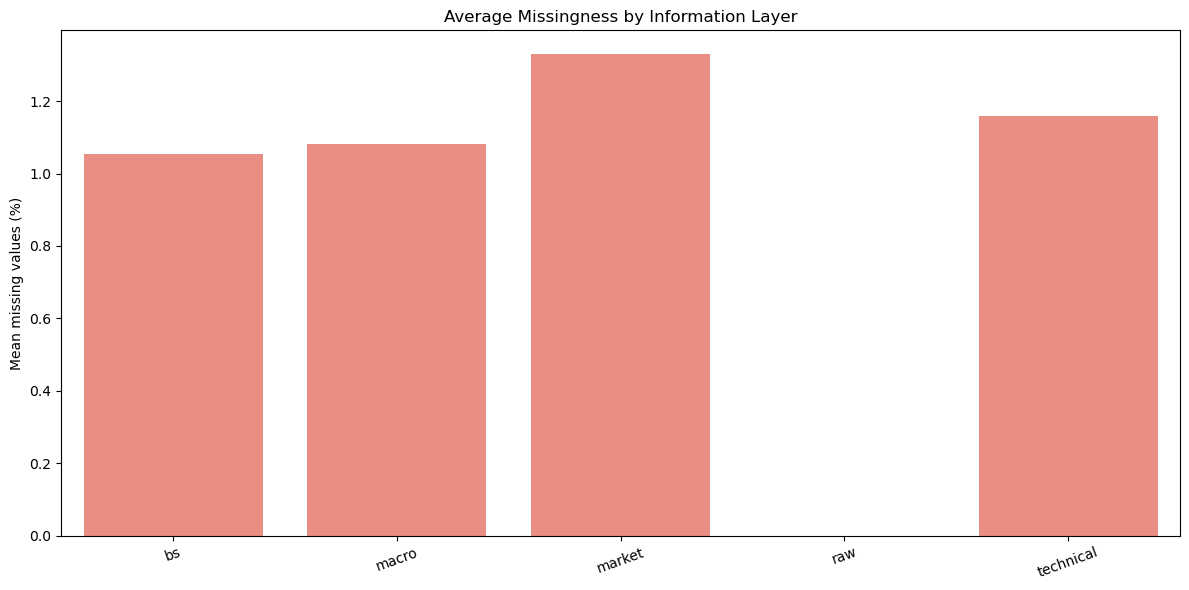

In [33]:
# Feature missingness by information layer

missing_rows = []

for layer_name, feature_cols in layer_feat.items():
    for col in feature_cols: missing_rows.append({"Layer": layer_name,
                                                  "Feature": col,
                                                  "Missing_Pct": panel[col].isna().mean() * 100})
missingness = pd.DataFrame(missing_rows)

#Plot missingness on a bar graph
plt.figure(figsize=(12, 6))
sns.barplot(data=missingness.groupby("Layer", as_index=False)["Missing_Pct"].mean(),
            x="Layer", y="Missing_Pct", color="salmon")
plt.title("Average Missingness by Information Layer")
plt.ylabel("Mean missing values (%)")
plt.xlabel("")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

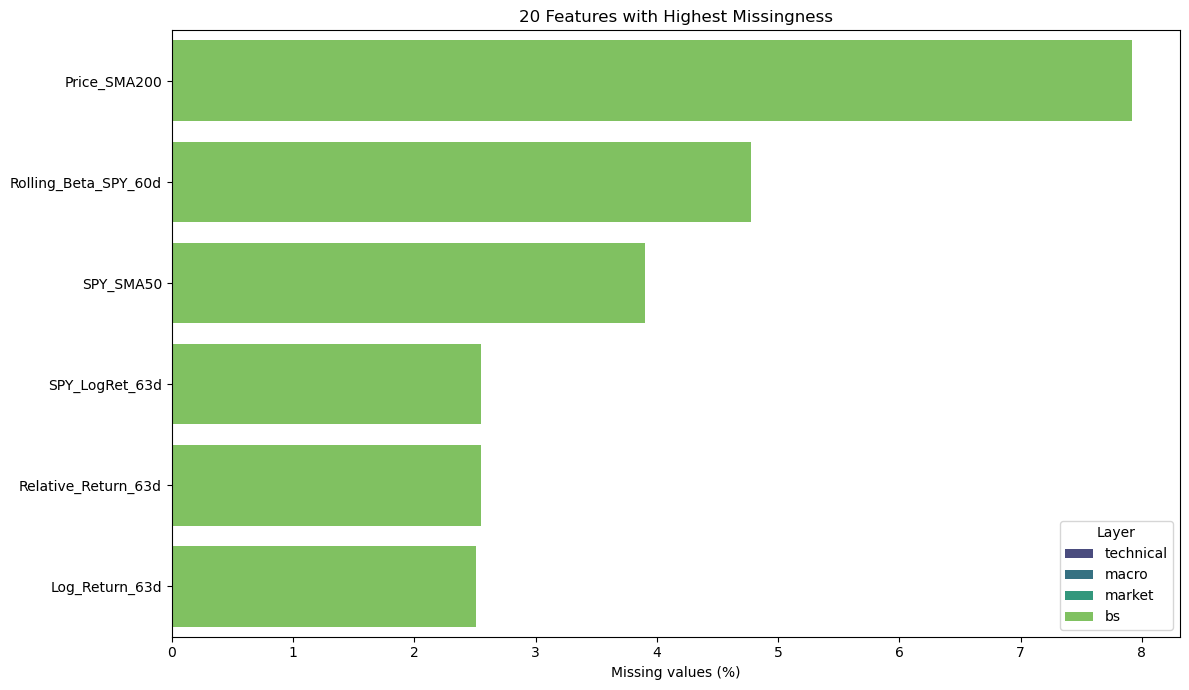

In [34]:
top_missing = missingness.sort_values("Missing_Pct", ascending=False).head(20)
plt.figure(figsize=(12, 7))
sns.barplot(data=top_missing, y="Feature", x="Missing_Pct", hue="Layer",
            palette="viridis", dodge=False)
plt.title("20 Features with Highest Missingness")
plt.xlabel("Missing values (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()

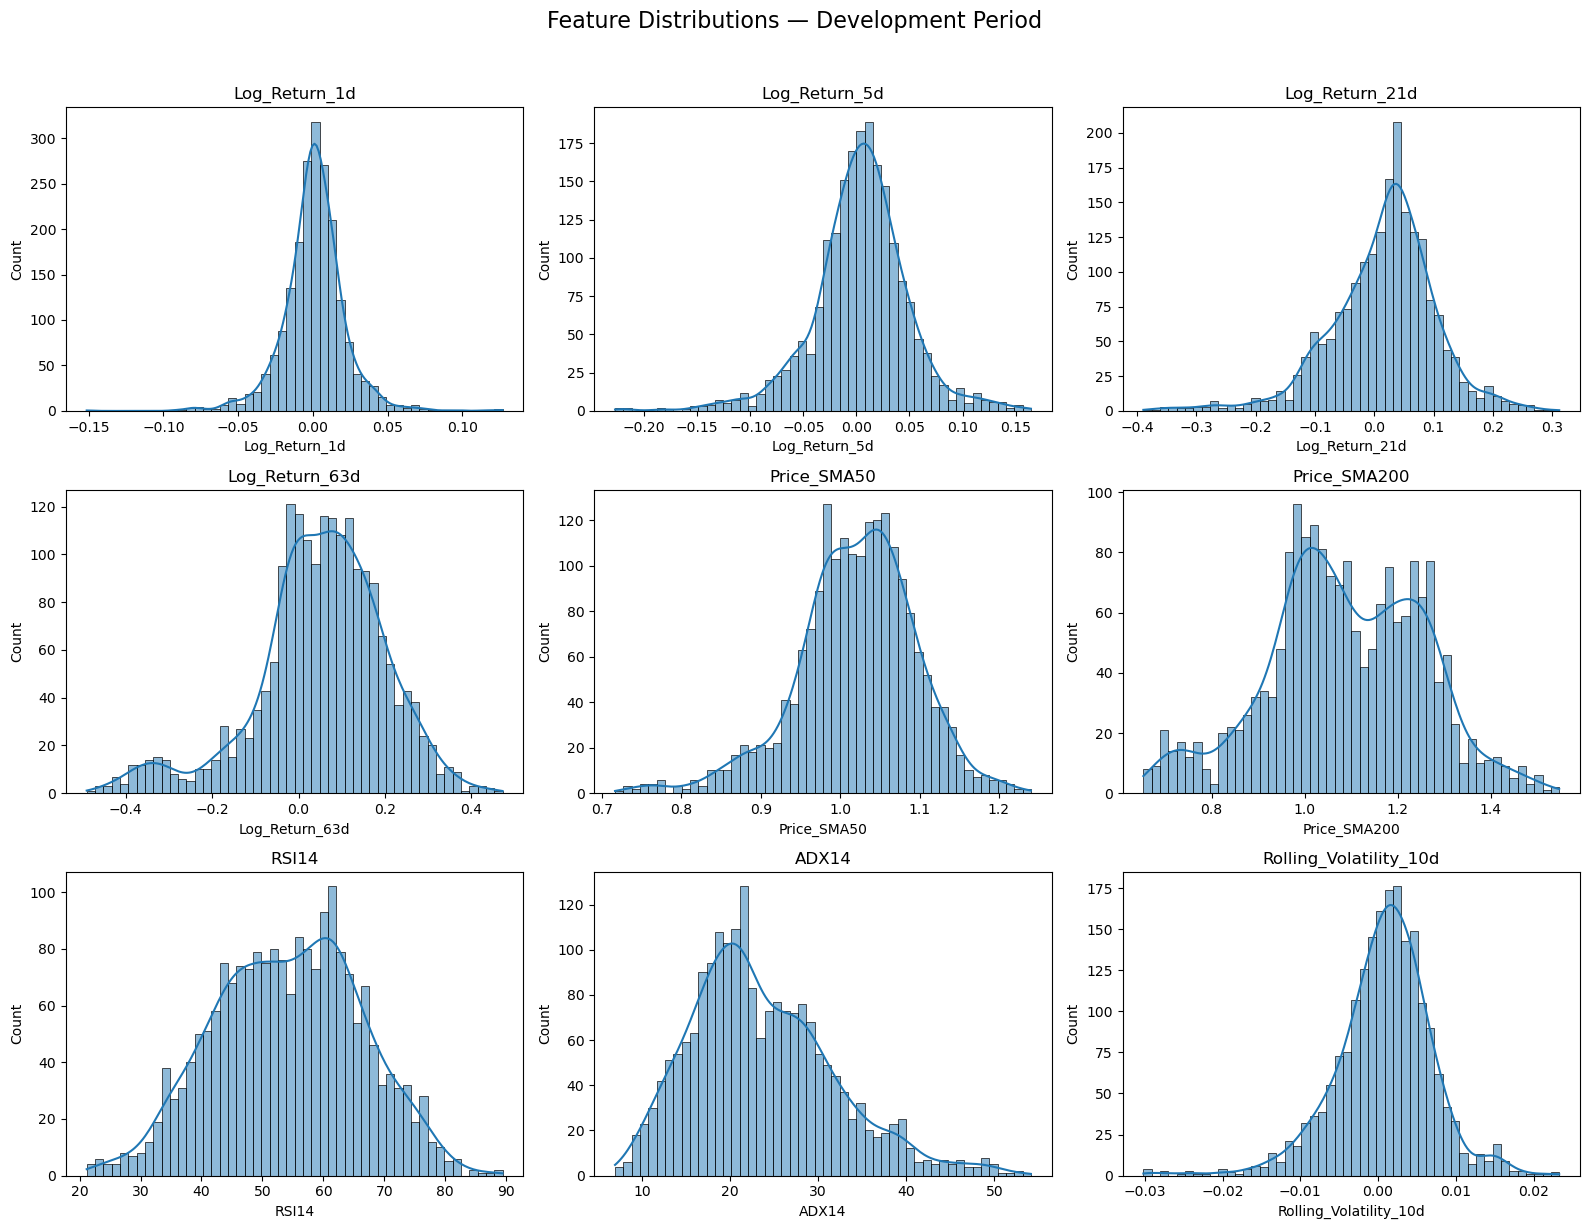

In [35]:
#Technical indicator's distribution

eda_cols = ["Log_Return_1d", "Log_Return_5d", "Log_Return_21d", "Log_Return_63d", "Price_SMA50",
            "Price_SMA200", "RSI14", "ADX14", "Rolling_Volatility_10d", "Rolling_Volatility_60d", 
            "Relative_Volume_20d", "Relative_Volume_60d", "Bollinger_PctB", "OBV_Slope_10d" ]
#look at distribution within 8 years timeframe
tech_eda = panel.loc[panel["Date"] < train_end, eda_cols].sample(
    n=min(20000, panel.loc[panel["Date"] < train_end, eda_cols].dropna(how="all").shape[0]),
    random_state=42)

#Plot distributions
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, col in zip(axes.flat, eda_cols):
    sns.histplot(tech_eda[col].dropna(), bins=50, kde=True, ax=ax)
    ax.set_title(col)
    ax.set_ylabel("Count")
for ax in axes.flat[len(eda_cols):]:
    ax.axis("off")
fig.suptitle("Feature Distributions — Development Period", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

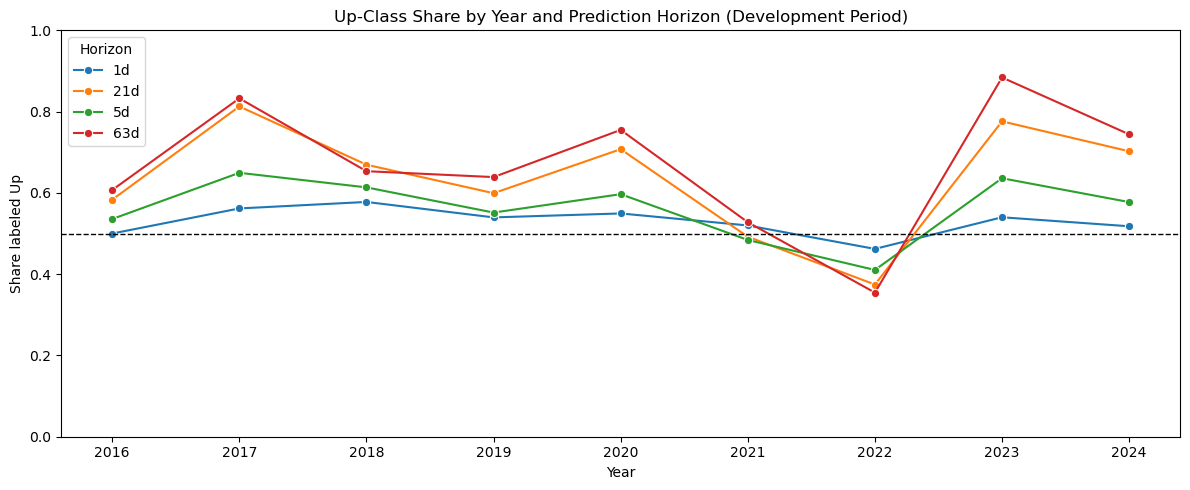

In [36]:
# Target balance by horizon and year, train/valid period only
target_balance = panel.loc[panel["Date"] < train_end].copy()
target_balance["Year"] = target_balance["Date"].dt.year
balance = (target_balance.melt(id_vars=["Date", "Year"],
                               value_vars=[f"direction_{h}d" for h in horizons],
                               var_name="Horizon", value_name="Direction")
           .dropna(subset=["Direction"]) )

balance["Horizon"] = balance["Horizon"].str.extract(r"direction_(\d+)d")[0] + "d"
year_balance = balance.groupby(["Year", "Horizon"])["Direction"].mean().reset_index()

#Plot
plt.figure(figsize=(12, 5))
sns.lineplot(data=year_balance, x="Year", y="Direction", hue="Horizon", marker="o")
plt.axhline(0.5, color="black", linestyle="--", linewidth=1)
plt.title("Up-Class Share by Year and Prediction Horizon (Development Period)")
plt.ylabel("Share labeled Up")
plt.xlabel("Year")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

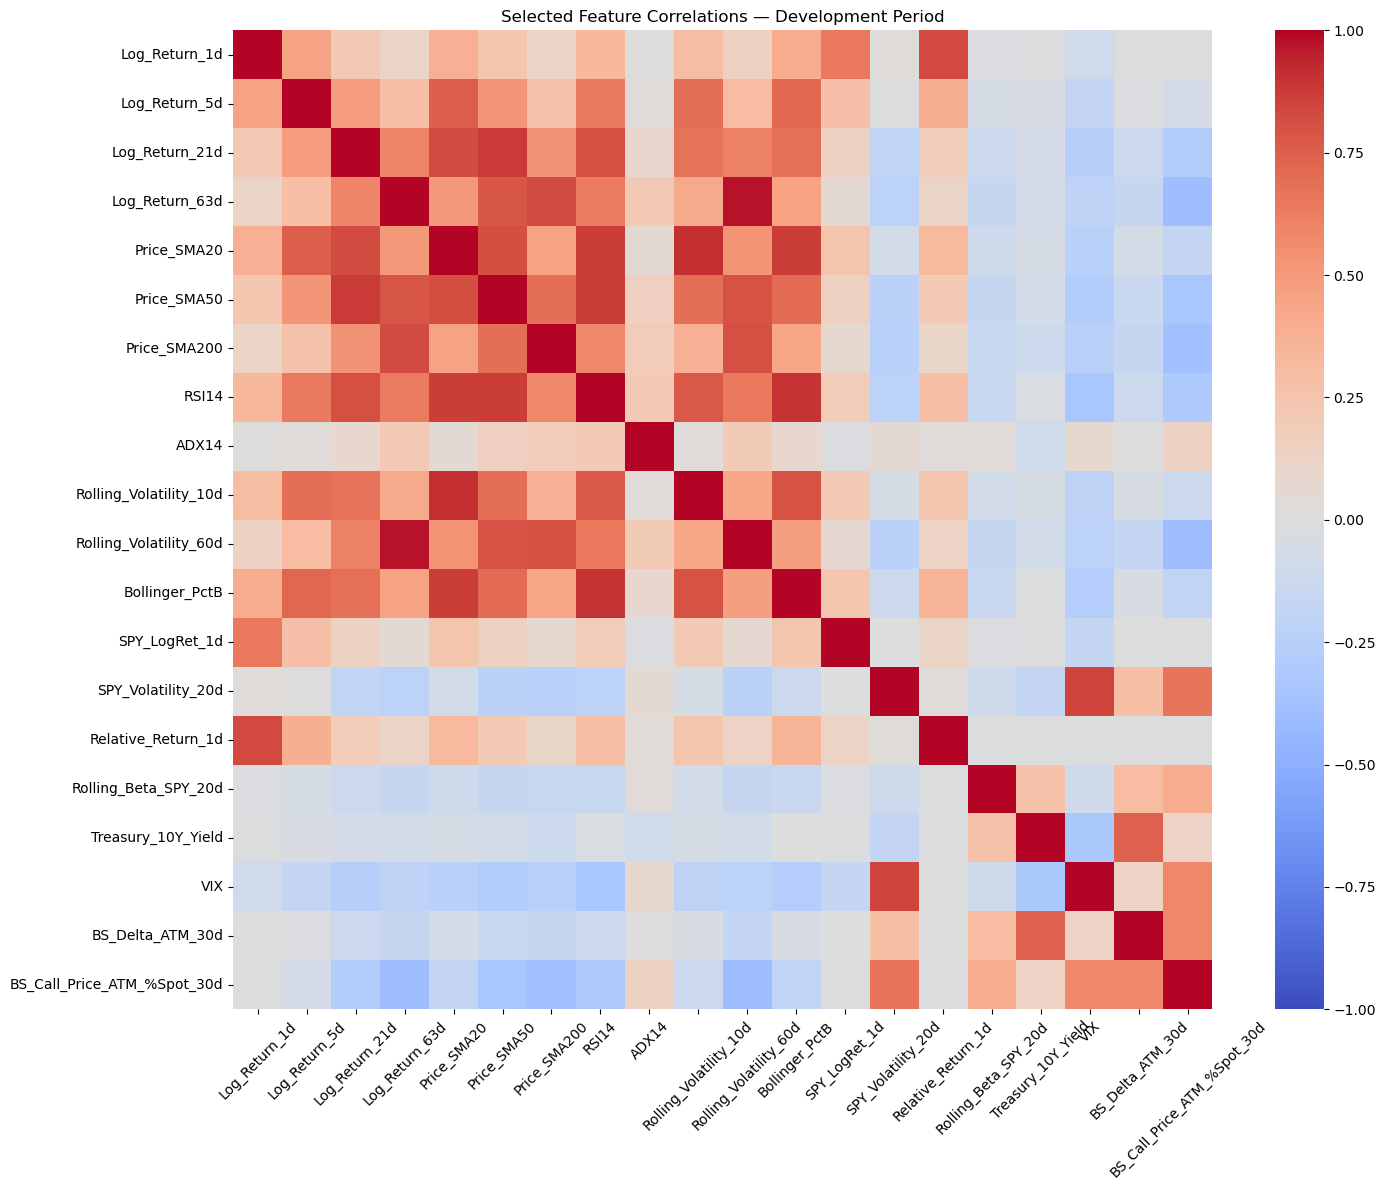

In [37]:
# Correlation heatmap on a manageable selection of engineered features within 8 years time
corr_cols = [
    "Log_Return_1d", "Log_Return_5d", "Log_Return_21d", "Log_Return_63d",
    "Price_SMA20", "Price_SMA50", "Price_SMA200", "RSI14", "ADX14",
    "Rolling_Volatility_10d", "Rolling_Volatility_60d", "Bollinger_PctB",
    "SPY_LogRet_1d", "SPY_Volatility_20d", "Relative_Return_1d",
    "Rolling_Beta_SPY_20d", "Treasury_10Y_Yield", "VIX",
    "BS_Delta_ATM_30d", "BS_Call_Price_ATM_%Spot_30d"]

corr = panel.loc[panel["Date"] < train_end, corr_cols].corr()
plt.figure(figsize=(15, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True)
plt.title("Selected Feature Correlations — Development Period")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [38]:
#This Section: A look at VIF scores 

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
import numpy as np
import pandas as pd

# Use development-period observations only; final holdout is excluded.
vif_cols = ["Log_Return_1d", "SPY_LogRet_1d", "Relative_Return_1d", "BS_Delta_ATM_30d", "VIX",
            "Rolling_Volatility_20d", "Treasury_10Y_Yield", "Rolling_Beta_SPY_20d",
            "VIX_Change_1d", "SPY_LogRet_5d", "Log_Return_5d", "Treasury_10Y_2Y_Spread",]

# Keep only columns that exist in this version of the notebook.
vif_cols = [c for c in vif_cols if c in panel.columns]

#keep within train/valid set
vif_df = panel.loc[panel["Date"] < train_end, vif_cols].copy()

# Ensure numeric data and use the same rows for every feature.
vif_df = vif_df.apply(pd.to_numeric, errors="coerce")
vif_df = vif_df.replace([np.inf, -np.inf], np.nan).dropna()

# Remove constant columns, which cannot be meaningfully assessed by VIF.
vif_df = vif_df.loc[:, vif_df.nunique() > 1]

X_vif = add_constant(vif_df, has_constant="add")

vif_results = pd.DataFrame({ "Feature": X_vif.columns,
                            "VIF": [variance_inflation_factor(X_vif.values, i)
                                    for i in range(X_vif.shape[1]) ], })

vif_results = (vif_results[vif_results["Feature"] != "const"]
               .sort_values("VIF", ascending=False).reset_index(drop=True) )

print(f"VIF observations used: {len(vif_df):,}")
print(f"Latest VIF date: {panel.loc[vif_df.index, 'Date'].max()}")
display(vif_results)

VIF observations used: 1,992
Latest VIF date: 2024-08-30 00:00:00


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/stats/outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,Feature,VIF
0,Log_Return_1d,inf
1,SPY_LogRet_1d,inf
2,Relative_Return_1d,inf
3,BS_Delta_ATM_30d,8.837583
4,Treasury_10Y_Yield,4.450681
5,Treasury_10Y_2Y_Spread,4.235903
6,Rolling_Volatility_20d,3.985756
7,VIX,3.323790
8,VIX_Change_1d,2.518903
9,SPY_LogRet_5d,2.336109


In [39]:
#Check correlation of suspicious columns
check_cols = [
    "Treasury_10Y_Yield",
    "Treasury_10Y_2Y_Spread",
    "Treasury_3M_Yield",
    "VIX",
    "Rolling_Volatility_20d",
    "Rolling_Beta_SPY_20d",
]

check_cols = [c for c in check_cols if c in panel.columns]

display(panel[check_cols].corr().round(3))

,Treasury_10Y_Yield,Treasury_10Y_2Y_Spread,Treasury_3M_Yield,VIX,Rolling_Volatility_20d,Rolling_Beta_SPY_20d
Treasury_10Y_Yield,1.000,-0.522,0.903,-0.253,0.106,0.234
Treasury_10Y_2Y_Spread,-0.522,1.000,-0.758,-0.031,-0.257,-0.192
Treasury_3M_Yield,0.903,-0.758,1.000,-0.195,0.094,0.191
VIX,-0.253,-0.031,-0.195,1.000,0.565,-0.108
Rolling_Volatility_20d,0.106,-0.257,0.094,0.565,1.000,0.375
Rolling_Beta_SPY_20d,0.234,-0.192,0.191,-0.108,0.375,1.000


In [40]:
#These Next Sections: Feature to target correlation

# limit to train/valid period.
dev = panel.loc[panel["Date"] < train_end].copy()

# 2. Exclude target-related and non-feature columns 
excluded_exact = {"Date", "Adj_Close"}

excluded_prefixes = ("fwd_ret_", "direction_", "label_end_")

feature_cols = [c for c in dev.columns if c not in excluded_exact 
                and not c.startswith(excluded_prefixes)
                and pd.api.types.is_numeric_dtype(dev[c]) ]

target_cols = [f"direction_{h}d" for h in horizons if f"direction_{h}d" in dev.columns]

print("Development rows:", len(dev))
print("Features checked:", len(feature_cols))
print("Targets checked:", target_cols)

Development rows: 2012
Features checked: 47
Targets checked: ['direction_1d', 'direction_5d', 'direction_21d', 'direction_63d']


In [41]:
# Calculate feature-to-target Pearson correlations.
results = []

for target in target_cols:
    for feature in feature_cols:
        valid = dev[[feature, target]].dropna()

        # Skip insufficient data or constant columns.
        if len(valid) < 100:
            continue
        if valid[feature].nunique() < 2 or valid[target].nunique() < 2:
            continue
        #get correlation values
        corr_value = valid[feature].corr(valid[target])
        #put in dict
        results.append({
            "Horizon": target.replace("direction_", ""),
            "Feature": feature,
            "Correlation": corr_value,
            "Abs_Correlation": abs(corr_value),
            "Rows_Used": len(valid)})

target_corr = pd.DataFrame(results)

In [42]:
#A look at the strongest positive and negative associations per horizon.
for horizon in [f"{h}d" for h in horizons]:
    subset = target_corr[target_corr["Horizon"] == horizon]

    print(f"Target: direction_{horizon}")

    print("\nTop 10 positive correlations:")
    print(subset.sort_values("Correlation", ascending=False)
          [["Feature", "Correlation", "Rows_Used"]].head(10).round(4).to_string(index=False))

    print("\nTop 10 negative correlations:")
    print(subset.sort_values("Correlation", ascending=True)
          [["Feature", "Correlation", "Rows_Used"]].head(10).round(4).to_string(index=False))

Target: direction_1d

Top 10 positive correlations:
               Feature  Correlation  Rows_Used
    Relative_Return_1d       0.0336       2011
         VIX_Change_1d       0.0272       2011
Treasury_10Y_2Y_Spread       0.0259       2011
   Relative_Return_63d       0.0229       1949
    SPY_Volatility_20d       0.0192       1992
                   VIX       0.0174       2012
          Price_SMA200       0.0108       1813
         VIX_Change_5d       0.0098       2007
Rolling_Volatility_60d       0.0095       1952
                 ADX14       0.0056       1986

Top 10 negative correlations:
              Feature  Correlation  Rows_Used
                 Open      -0.0556       2012
                 High      -0.0547       2012
                  Low      -0.0545       2012
                  OBV      -0.0531       2012
        SPY_LogRet_1d      -0.0420       2011
BS_Call_Price_ATM_60d      -0.0419       1992
BS_Call_Price_ATM_30d      -0.0417       1992
       SPY_LogRet_63d      -0.03

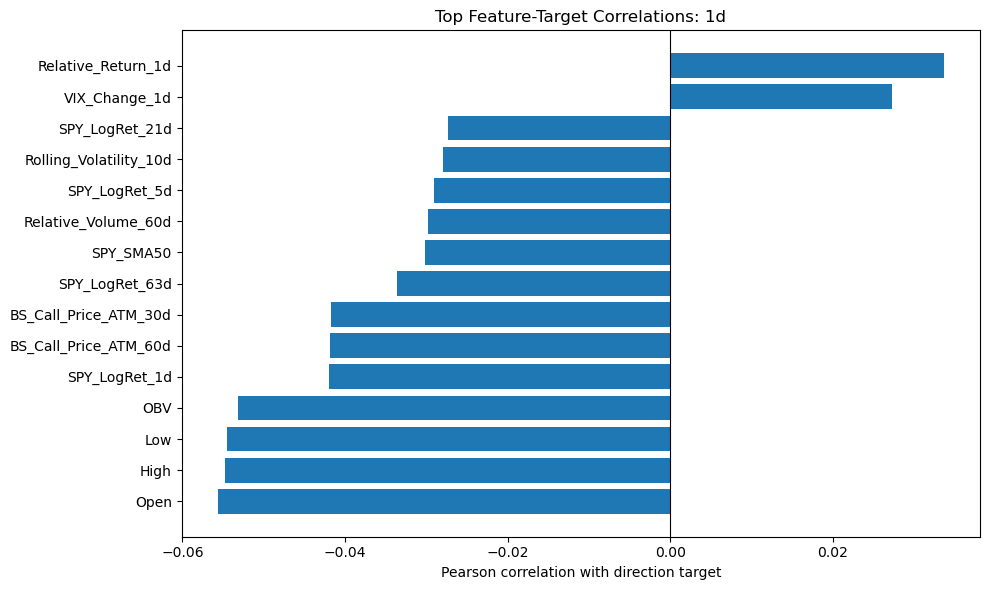

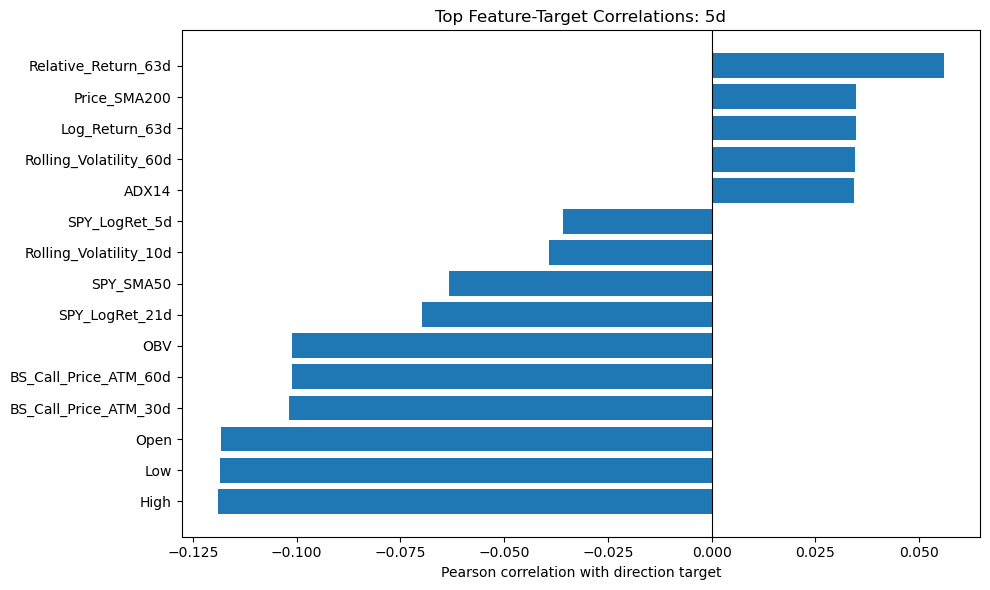

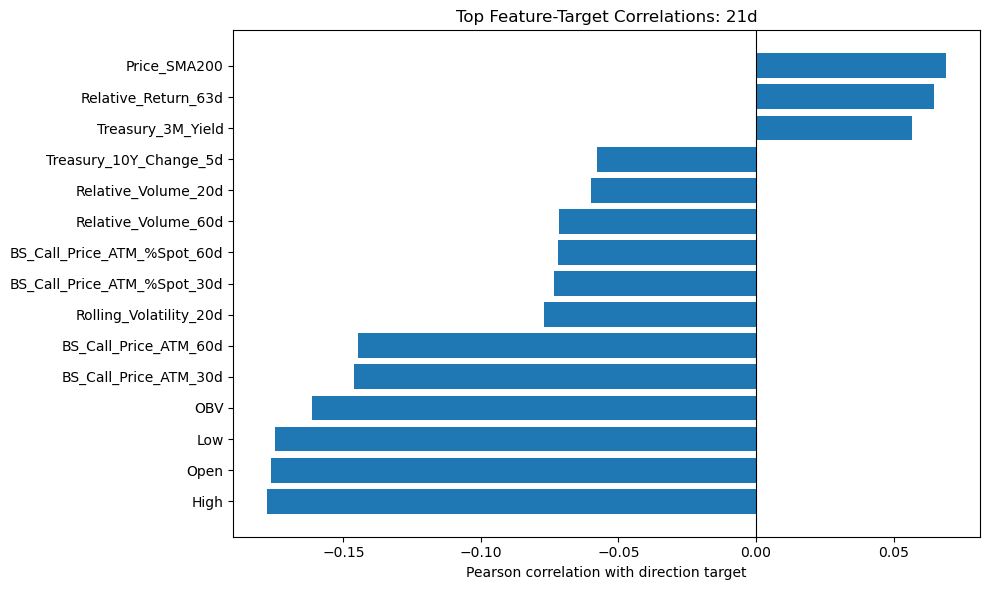

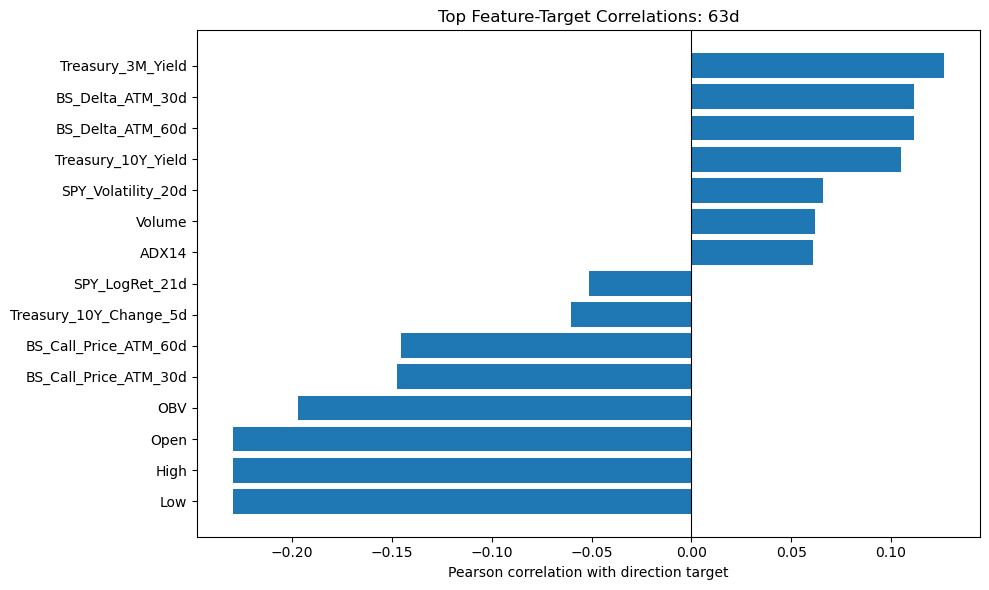

In [43]:
# Visualize the 15 strongest absolute correlations for each horizon.
for horizon in [f"{h}d" for h in horizons]:
    subset = (target_corr[target_corr["Horizon"] == horizon]
              .nlargest(15, "Abs_Correlation").sort_values("Correlation"))

    if subset.empty:
        continue

    plt.figure(figsize=(10, 6))
    plt.barh(subset["Feature"], subset["Correlation"])
    plt.axvline(0, color="black", linewidth=0.8)
    plt.xlabel("Pearson correlation with direction target")
    plt.title(f"Top Feature-Target Correlations: {horizon}")
    plt.tight_layout()
    plt.show()

# Walk-Forward Multi-Layer ML

In [45]:
# Define time frame we're working with
all_dates = pd.DatetimeIndex(sorted(panel["Date"].dropna().unique() ))
work_dates = all_dates[all_dates < train_end] #we're working w only train/valid set

In [203]:
#Funcrion to make our expanding walk-forward folds
def make_folds(dates, step_size=63, min_train_rows=252):
    dates = pd.DatetimeIndex(dates).sort_values().unique()
    folds = []
    # Start test folds only after the work (train/valid set) period
    start_pos = min_train_rows
    while start_pos < len(dates):
        end_pos = min(start_pos + step_size, len(dates))
        test_dates = dates[start_pos:end_pos]
        if len(test_dates):
            folds.append((pd.Timestamp(test_dates[0]), pd.Timestamp(test_dates[-1]),
                          len(folds) + 1))
        start_pos = end_pos
    return folds

#Make the folds
folds = make_folds(work_dates)
fold_summary = pd.DataFrame(folds, columns=["Test_Start", "Test_End", "Fold"])
display(fold_summary)
print(f"Development dates: {len(work_dates):,}")
print(f"Walk-forward folds: {len(folds)}")
print("Final holdout begins:", train_end.date())

,Test_Start,Test_End,Fold
0,2017-09-01,2017-11-30,1
1,2017-12-01,2018-03-05,2
2,2018-03-06,2018-06-04,3
3,2018-06-05,2018-08-31,4
4,2018-09-04,2018-11-30,5
5,2018-12-03,2019-03-06,6
6,2019-03-07,2019-06-05,7
7,2019-06-06,2019-09-04,8
8,2019-09-05,2019-12-03,9
9,2019-12-04,2020-03-05,10


Development dates: 2,012
Walk-forward folds: 28
Final holdout begins: 2024-09-01


In [47]:
#A function to initiate/build all models w preprocessing choices

def build_models():
    models={}
    
    #set sof models to use
    base_models = {
        "Naive Majority": DummyClassifier(strategy="most_frequent"),
        "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced",
                                                 random_state=42),
        "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, 
                                               class_weight="balanced_subsample", n_jobs=-1,
                                               random_state=42),
        "XGBoost": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, 
                                subsample=0.8, colsample_bytree=0.8, objective="binary:logistic",
                                eval_metric="logloss", n_jobs=-1, random_state=42) }
    #sets of scaling techniques
    scalers = {
        "No Scaling": None,
        "StandardScaler": StandardScaler(),
        "RobustScaler": RobustScaler() }

    for model_name, base_model in base_models.items():
        #Naive model doesnt use scalers
        if model_name == "Naive Majority":
            models[model_name] = base_model
            continue
            
        for scaler_name, scaler in scalers.items():
            #build a separate pipeline for each configuration
            steps = []
            if scaler is not None:
                steps.append(("scaler", scaler))

            steps.append(("model",clone( base_model)))
            
            models[f"{model_name} | {scaler_name}"] = Pipeline(steps)
            
    return models

In [48]:
#A function to set up all our metric evaluations at once
def metric_row(y_true, y_pred, y_prob=None):
    
    out = {"Accuracy": accuracy_score(y_true, y_pred),
           "Balanced_Accuracy": balanced_accuracy_score(y_true, y_pred),
           "Up_Precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
           "Up_Recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
           "Up_F1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),}
    
    out["ROC_AUC"] = (roc_auc_score(y_true, y_prob) if y_prob is not None 
                      and len(np.unique(y_true)) == 2 else np.nan)
    return out

In [49]:
#Set up our models
models = build_models()
print("Models to evaluate:")
for name in models:
    print("-", name)

Models to evaluate:
- Naive Majority
- Logistic Regression | No Scaling
- Logistic Regression | StandardScaler
- Logistic Regression | RobustScaler
- Random Forest | No Scaling
- Random Forest | StandardScaler
- Random Forest | RobustScaler
- XGBoost | No Scaling
- XGBoost | StandardScaler
- XGBoost | RobustScaler


In [235]:
#Give model colors for later visualizations
model_names = list(models.keys())
palette = sns.color_palette("Paired", n_colors=len(model_names))
model_colors = dict(zip(model_names, palette))

In [51]:
#This Section: running models across horizons 

#Set up variables to store results
all_metrics = []
all_predictions = []
all_reports = []
all_confusions = []

#use the layered feature previously made
for layer_name, feature_cols in layer_feat.items():
    print(f"\nLayer: {layer_name} ({len(feature_cols)} numeric features)")
    
    for h in horizons:
        
        target_col = f"direction_{h}d"
        label_end_col = f"label_end_{h}d"
        model_dict = build_models()

        for fold_start, fold_end, fold_num in folds: #the walk-forward folds previosuly made
            test_mask = panel["Date"].between(fold_start, fold_end, inclusive="both")
            # Keep only rows whose target has matured.
            test_df = panel.loc[test_mask & panel[target_col].notna()].copy()
            if test_df.empty:
                continue

            # Purge: every training target must be fully known before test start.
            train_mask = ((panel["Date"] < fold_start) & panel[target_col].notna()
                          & panel[label_end_col].notna() & (panel[label_end_col] < fold_start) )
            train_df = panel.loc[train_mask].copy()
            if len(train_df) < 252: #252 = 1 year's worth of trading days
                continue

            #Set up train/test sets
            x_train = train_df[feature_cols]
            y_train = train_df[target_col].astype(int)
            x_test = test_df[feature_cols]
            y_test = test_df[target_col].astype(int)

            for model_name, estimator in model_dict.items():

                #handling missing value without imputation

                #Logreg cannot fit or predict with NaNs
                need_complete_rows = (model_name.startswith("Logistic Regression"))
                #make new sets where we drop all rows with null
                if need_complete_rows:
                    train_valid = x_train.notna().all(axis=1)
                    test_valid = x_test.notna().all(axis=1)
                    x_train_model = x_train.loc[train_valid]
                    y_train_model = y_train.loc[train_valid]
                    x_test_model = x_test.loc[test_valid]
                    y_test_model = y_test.loc[test_valid]
                else: #use normal set with nulls for models capable of handling NaNs
                    x_train_model = x_train
                    y_train_model = y_train
                    x_test_model = x_test
                    y_test_model = y_test

                #safeguard
                if len(x_train_model) < 252 or len(x_test_model) == 0:
                    continue
                if y_train_model.nunique() < 2:
                    continue

                #the actual fit and predict
                if model_name == "Naive Majority":
                    estimator.fit(np.zeros((len(y_train_model), 1)), y_train_model)
                    pred = estimator.predict(np.zeros((len(y_test_model), 1))).astype(int)
                    prob = None
                else: 
                    
                    estimator.fit(x_train_model, y_train_model)
                    pred = estimator.predict(x_test_model).astype(int)
                    prob = None
                    
                    if hasattr(estimator, "predict_proba"):
                        try:
                            prob = estimator.predict_proba(x_test_model)[:, 1]
                        except (ValueError, IndexError):
                            prob = None

                #calculate metrics on the rows actually evaluated
                row = {
                    "Layer": layer_name, "Horizon": h, "Fold": fold_num,
                    "Test_Start": fold_start, "Test_End": fold_end,
                    "Model": model_name, "N_Train": len(y_train_model), 
                    "N_Test": len(y_test_model), 
                    "N_Train_Excluded_Missing": len(y_train) - len(y_train_model),
                    "N_Test_Excluded_Missing": len(y_test) - len(y_test_model),
                    **metric_row(y_test_model, pred, prob) }
                
                all_metrics.append(row)
                #Store predictions only for observations actually evaluated
                pred_frame = test_df.loc[y_test_model.index, ["Date"]].copy()
                
                pred_frame["Layer"] = layer_name
                pred_frame["Horizon"] = h
                pred_frame["Fold"] = fold_num
                pred_frame["Model"] = model_name
                pred_frame["y_true"] = y_test_model.to_numpy()
                pred_frame["y_pred"] = pred
                pred_frame["y_prob_up"] = prob if prob is not None else np.nan
                
                all_predictions.append(pred_frame)
                #classification report
                report = classification_report(y_test_model, pred, labels=[0, 1], 
                                               target_names=["Down", "Up"],
                                               output_dict=True, zero_division=0)
                
                #store results into one place
                all_reports.append({
                    "Layer": layer_name, "Horizon": h, "Fold": fold_num, "Model": model_name,
                    "Down_Precision": report["Down"]["precision"],
                    "Down_Recall": report["Down"]["recall"],
                    "Down_F1": report["Down"]["f1-score"],
                    "Up_Precision_Report": report["Up"]["precision"],
                    "Up_Recall_Report": report["Up"]["recall"],
                    "Up_F1_Report": report["Up"]["f1-score"],
                    "Macro_F1": report["macro avg"]["f1-score"],
                    "Weighted_F1": report["weighted avg"]["f1-score"],})
                #for confusion matrix
                cm = confusion_matrix(y_test_model, pred, labels=[0, 1])
                all_confusions.append({
                    "Layer": layer_name, "Horizon": h, "Fold": fold_num, "Model": model_name,
                    "TN": cm[0, 0], "FP": cm[0, 1], "FN": cm[1, 0], "TP": cm[1, 1]})

#Put results into dataframe format
metrics_df = pd.DataFrame(all_metrics)
predictions_df = pd.concat(all_predictions, ignore_index=True) if all_predictions else pd.DataFrame()
reports_df = pd.DataFrame(all_reports)
confusions_df = pd.DataFrame(all_confusions)

if metrics_df.empty:
    raise RuntimeError("No metrics were generated")


Layer: raw (5 numeric features)


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:386: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2458: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2458: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2458: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2458: UserWarning: y_pred contains classes not in y_true
  warnings.warn


Layer: technical (20 numeric features)


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:386: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2458: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2458: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2458: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2458: UserWarning: y_pred contains classes not in y_true
  warnings.warn


Layer: market (32 numeric features)


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:386: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2458: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2458: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2458: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2458: UserWarning: y_pred contains classes not in y_true
  warnings.warn


Layer: macro (40 numeric features)


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:386: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2458: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2458: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2458: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2458: UserWarning: y_pred contains classes not in y_true
  warnings.warn


Layer: bs (44 numeric features)


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:386: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2458: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2458: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2458: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2458: UserWarning: y_pred contains classes not in y_true
  warnings.warn

In [52]:
# We got a lot of warnings
# Check whether each model predicts both classes
# and whether both classes exist in its actual test labels.

for (layer, horizon, model), group in predictions_df.groupby(["Layer", "Horizon", "Model"]):
    
    actual_classes = sorted(group["y_true"].dropna().unique())
    predicted_classes = sorted(group["y_pred"].dropna().unique())
    #Show model that only predicted 1 class/led to that warning
    if len(actual_classes) < 2 or len(predicted_classes) < 2:
        print(
            f"Layer={layer} | Horizon={horizon} | Model={model}\n"
            f"  Actual classes: {actual_classes}\n"
            f"  Predicted classes: {predicted_classes}\n"
            f"  Rows: {len(group)}\n")

Layer=bs | Horizon=1 | Model=Naive Majority
  Actual classes: [0, 1]
  Predicted classes: [1]
  Rows: 1697

Layer=bs | Horizon=5 | Model=Naive Majority
  Actual classes: [0, 1]
  Predicted classes: [1]
  Rows: 1697

Layer=bs | Horizon=21 | Model=Naive Majority
  Actual classes: [0, 1]
  Predicted classes: [1]
  Rows: 1697

Layer=bs | Horizon=63 | Model=Naive Majority
  Actual classes: [0, 1]
  Predicted classes: [1]
  Rows: 1697

Layer=macro | Horizon=1 | Model=Naive Majority
  Actual classes: [0, 1]
  Predicted classes: [1]
  Rows: 1697

Layer=macro | Horizon=5 | Model=Naive Majority
  Actual classes: [0, 1]
  Predicted classes: [1]
  Rows: 1697

Layer=macro | Horizon=21 | Model=Naive Majority
  Actual classes: [0, 1]
  Predicted classes: [1]
  Rows: 1697

Layer=macro | Horizon=63 | Model=Naive Majority
  Actual classes: [0, 1]
  Predicted classes: [1]
  Rows: 1697

Layer=market | Horizon=1 | Model=Naive Majority
  Actual classes: [0, 1]
  Predicted classes: [1]
  Rows: 1697

Layer=ma

In [53]:
#combine model comparisons across folds
aggregate_metrics = (metrics_df.groupby(["Layer", "Horizon", "Model"], as_index=False).agg(
    Accuracy_Mean=("Accuracy", "mean"),
    Accuracy_SD=("Accuracy", "std"),
    Balanced_Accuracy_Mean=("Balanced_Accuracy", "mean"),
    Up_Precision_Mean=("Up_Precision", "mean"),
    Up_Recall_Mean=("Up_Recall", "mean"),
    Up_F1_Mean=("Up_F1", "mean"),
    ROC_AUC_Mean=("ROC_AUC", "mean"),
    Folds=("Fold", "nunique") ))

display(aggregate_metrics.sort_values(["Horizon", "Layer", "Accuracy_Mean"], 
                                      ascending=[True, True, False]))

,Layer,Horizon,Model,Accuracy_Mean,Accuracy_SD,Balanced_Accuracy_Mean,Up_Precision_Mean,Up_Recall_Mean,Up_F1_Mean,ROC_AUC_Mean,Folds
3,bs,1,Naive Majority,0.530884,0.072243,0.500000,0.530884,1.000000,0.690750,NaN,27
8,bs,1,XGBoost | RobustScaler,0.504429,0.052153,0.505666,0.541111,0.539946,0.514736,0.506487,27
7,bs,1,XGBoost | No Scaling,0.503841,0.051265,0.505291,0.540306,0.542155,0.516600,0.509372,27
9,bs,1,XGBoost | StandardScaler,0.501490,0.050823,0.503286,0.538350,0.535935,0.511658,0.506252,27
4,bs,1,Random Forest | No Scaling,0.496787,0.058709,0.504117,0.543048,0.493353,0.465214,0.517264,27
...,...,...,...,...,...,...,...,...,...,...,...
195,technical,63,Random Forest | RobustScaler,0.450732,0.273151,0.486785,0.621467,0.540197,0.454014,0.577901,27
196,technical,63,Random Forest | StandardScaler,0.450732,0.273151,0.486785,0.621467,0.540197,0.454014,0.577975,27
190,technical,63,Logistic Regression | No Scaling,0.436362,0.279053,0.475740,0.444412,0.147640,0.182447,0.657042,23
191,technical,63,Logistic Regression | RobustScaler,0.395597,0.286740,0.437116,0.253384,0.158622,0.165189,0.501601,23


In [54]:
#Table gives naive model performance and non-naive model that performed
#best in each layer per horizon

# Summarize metrics across walk-forward folds
layer_summary = (metrics_df.groupby(["Layer", "Horizon", "Model"], as_index=False)
    .agg(Accuracy_Mean=("Accuracy", "mean"), Up_Precision_Mean=("Up_Precision", "mean"),
        Accuracy_SD=("Accuracy", "std"), Folds=("Fold", "nunique")))

# Separate the naive baseline
baseline = layer_summary[layer_summary["Model"] == "Naive Majority"].copy()

# Find the best non-baseline configuration for each layer/horizon
candidates = layer_summary[layer_summary["Model"] != "Naive Majority"].copy()

best_models = (candidates.sort_values("Accuracy_Mean", ascending=False)
               .drop_duplicates(["Layer", "Horizon"]))

# Keep baseline and best model per layer/horizon
table1 = pd.concat([baseline, best_models], ignore_index=True)

# Convert metrics to percentages
for col in ["Accuracy_Mean", "Up_Precision_Mean", "Accuracy_SD"]:
    table1[col] = (table1[col] * 100).round(2)

table1 = table1.sort_values(["Horizon", "Layer", "Model"]).reset_index(drop=True)

display(table1)

,Layer,Horizon,Model,Accuracy_Mean,Up_Precision_Mean,Accuracy_SD,Folds
0,bs,1,Naive Majority,53.09,53.09,7.22,27
1,bs,1,XGBoost | RobustScaler,50.44,54.11,5.22,27
2,macro,1,Naive Majority,53.09,53.09,7.22,27
3,macro,1,Random Forest | No Scaling,49.96,55.35,6.17,27
4,market,1,Naive Majority,53.09,53.09,7.22,27
5,market,1,XGBoost | RobustScaler,49.26,52.89,5.24,27
6,raw,1,Naive Majority,53.09,53.09,7.22,27
7,raw,1,XGBoost | RobustScaler,52.47,56.74,6.03,27
8,technical,1,Logistic Regression | RobustScaler,49.16,54.04,6.82,24
9,technical,1,Naive Majority,53.09,53.09,7.22,27


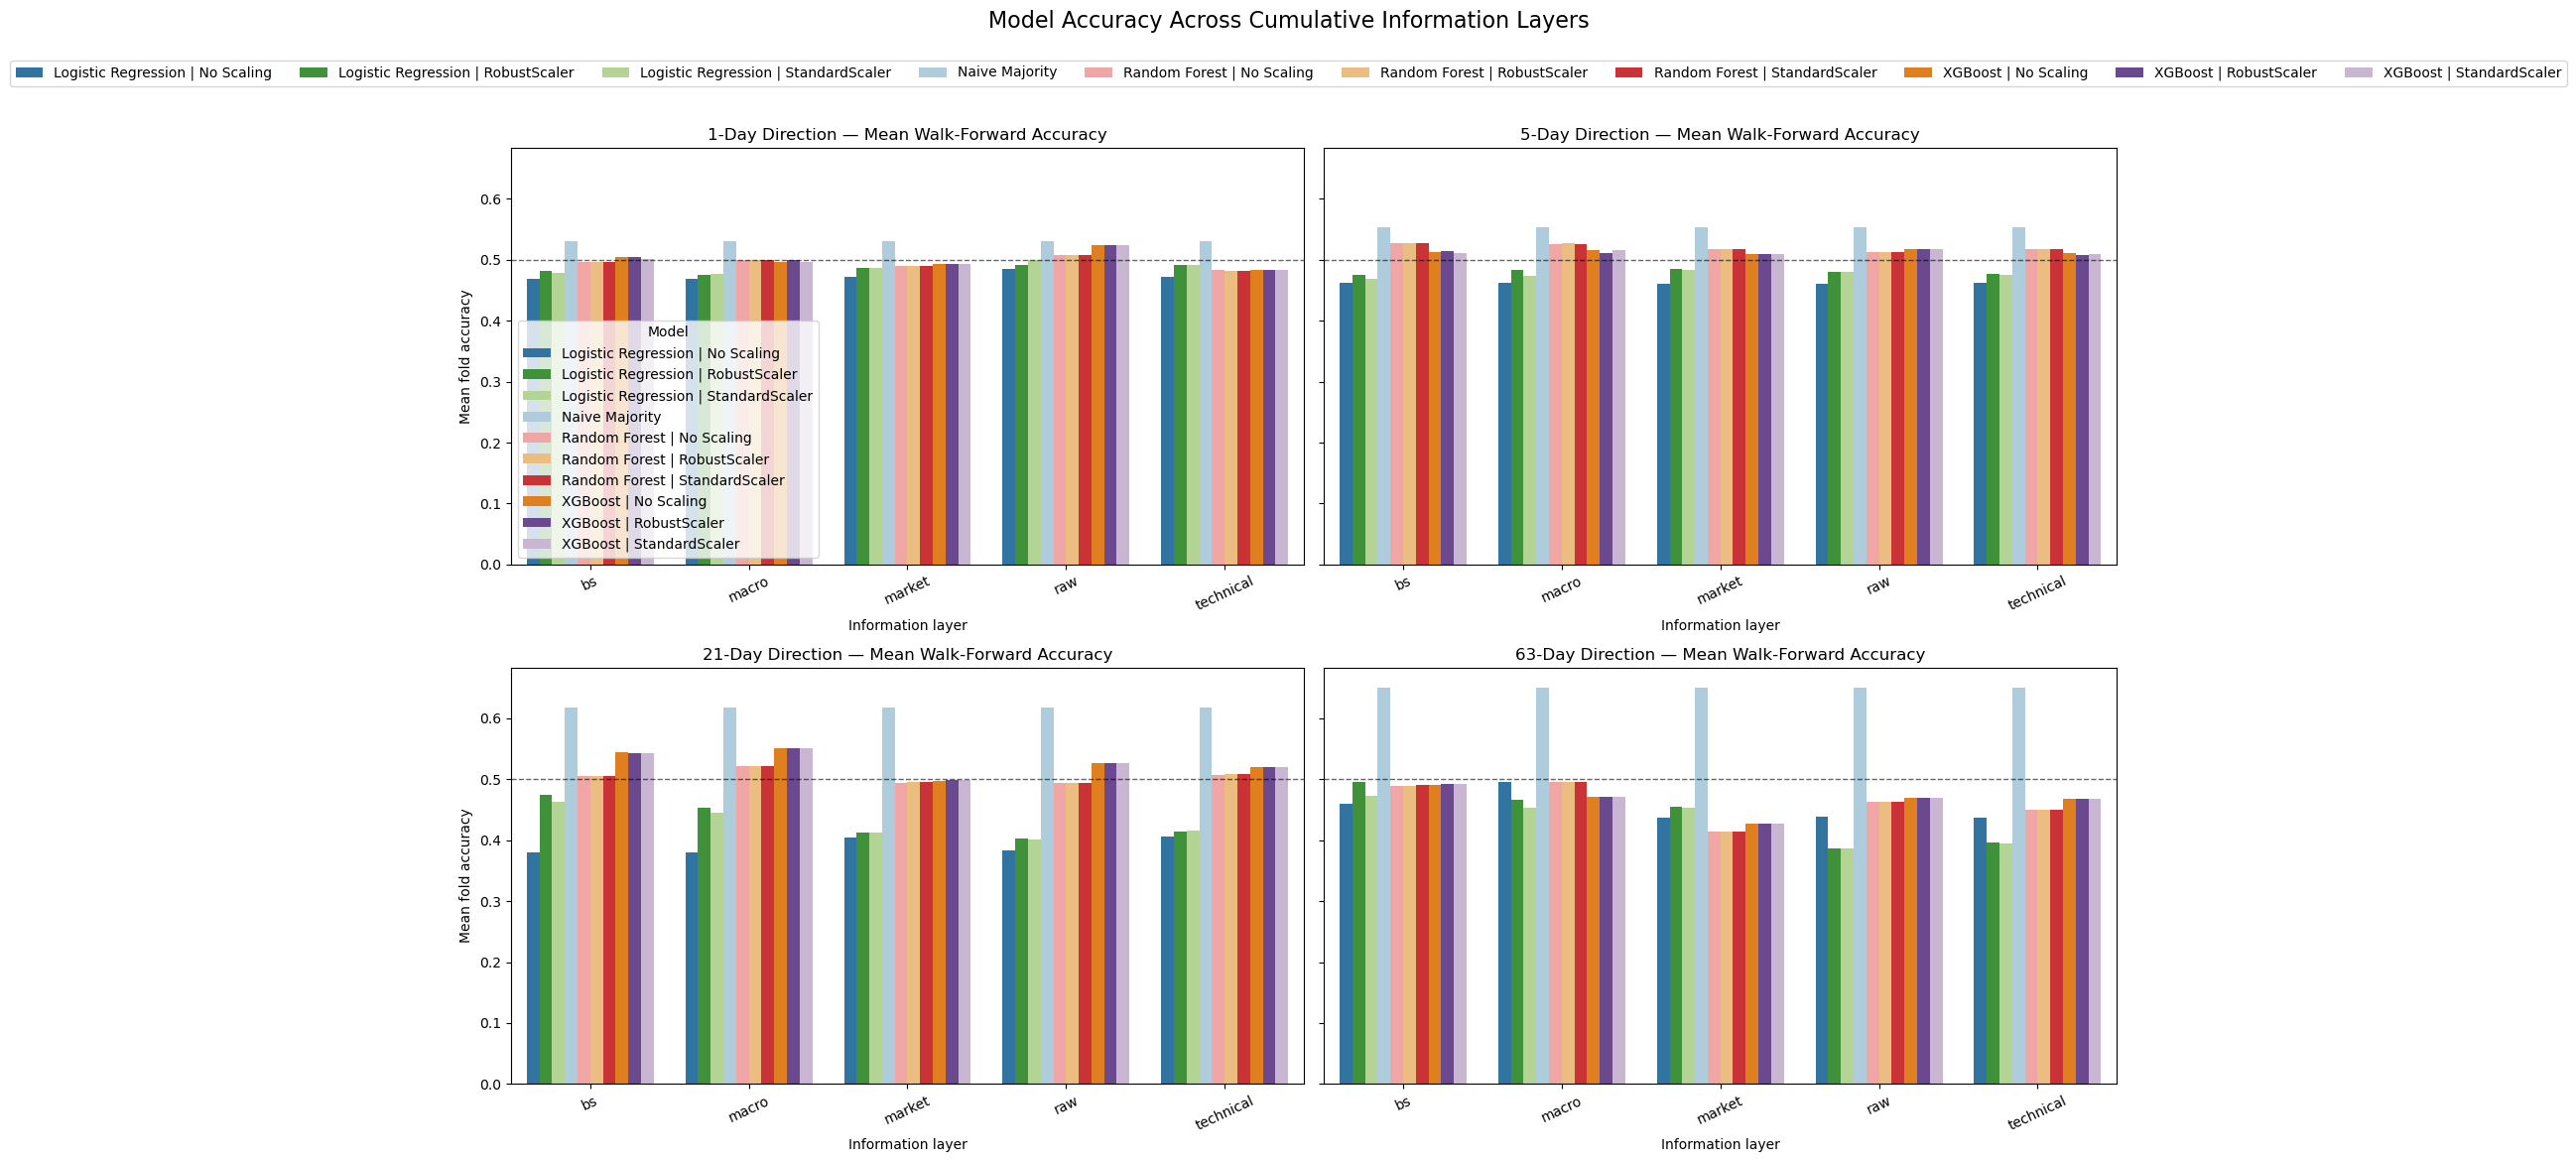

In [237]:
#Plot accuracy by layer and horizon, separate panel per horizon
fig, axes = plt.subplots(2, 2, figsize=(17, 11), sharey=True)
for ax, h in zip(axes.flat, horizons):
    sub = aggregate_metrics[aggregate_metrics["Horizon"] == h]
    sns.barplot(sub, x="Layer", y="Accuracy_Mean", hue="Model",
    palette=model_colors, ax=ax, errorbar=None)
    ax.set_title(f"{h}-Day Direction — Mean Walk-Forward Accuracy")
    ax.set_xlabel("Information layer")
    ax.set_ylabel("Mean fold accuracy")
    ax.tick_params(axis="x", rotation=25)
    ax.axhline(0.5, color="black", linestyle="--", linewidth=1, alpha=0.6)
    if ax.get_legend() and ax is not axes.flat[0]:
        ax.get_legend().remove()
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=len(labels), bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Model Accuracy Across Cumulative Information Layers", y=1.06, fontsize=16)
plt.tight_layout()
plt.show()

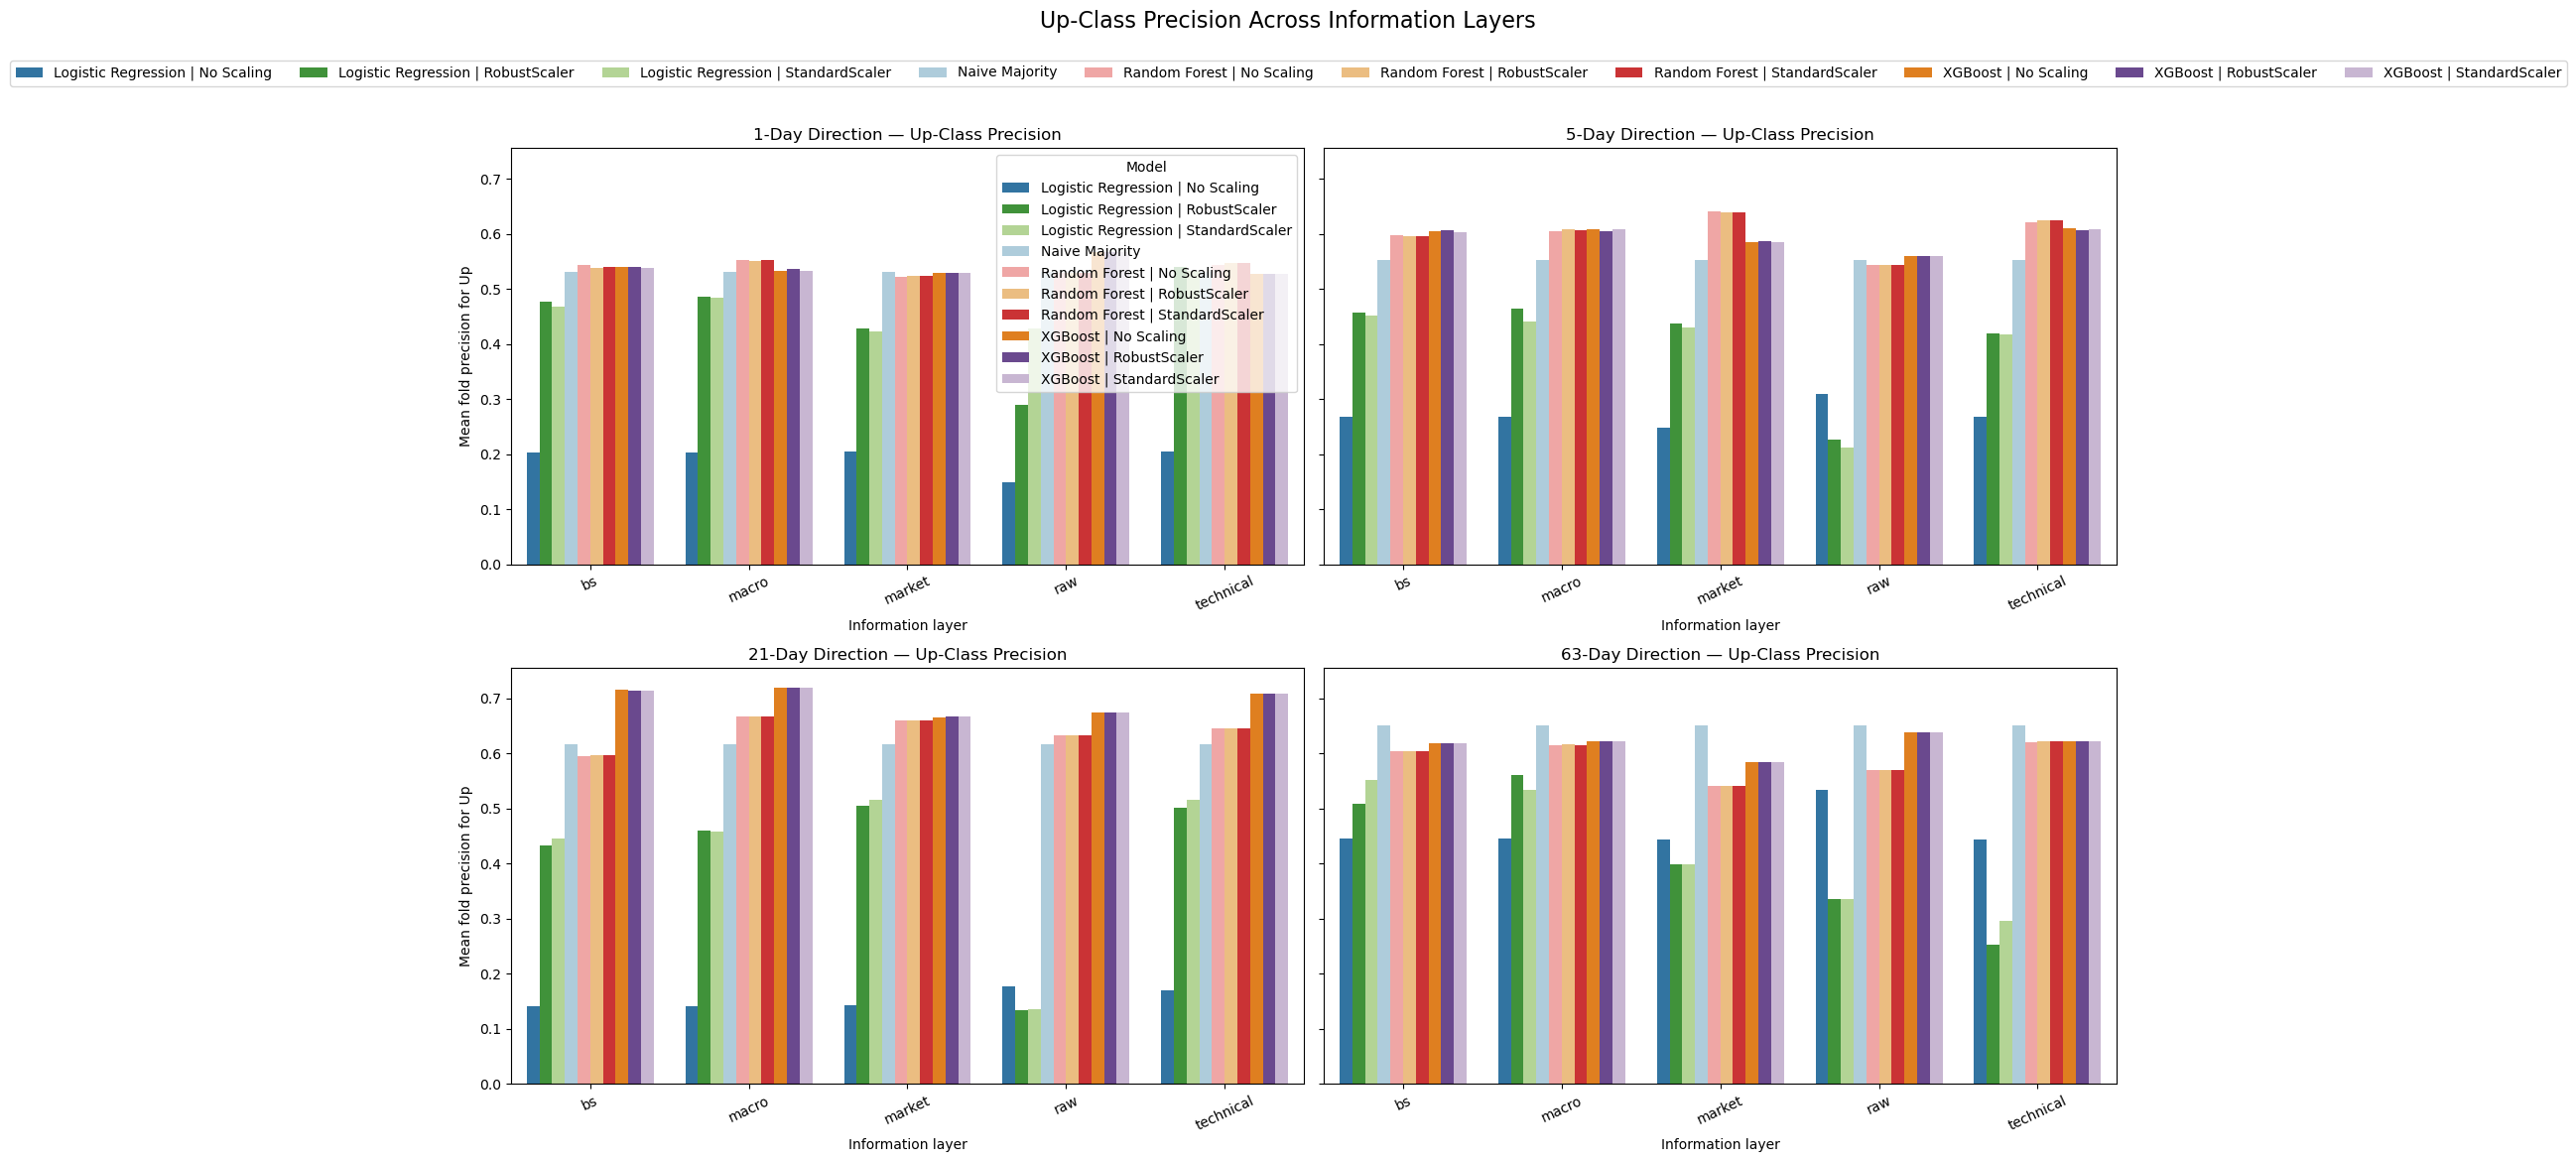

In [239]:
#Plot Up-class precision comparison
fig, axes = plt.subplots(2, 2, figsize=(17, 11), sharey=True)
for ax, h in zip(axes.flat, horizons):
    sub = aggregate_metrics[aggregate_metrics["Horizon"] == h]
    sns.barplot(data=sub, x="Layer", y="Up_Precision_Mean", hue="Model",
        palette=model_colors, ax=ax, errorbar=None)
    ax.set_title(f"{h}-Day Direction — Up-Class Precision")
    ax.set_xlabel("Information layer")
    ax.set_ylabel("Mean fold precision for Up")
    ax.tick_params(axis="x", rotation=25)
    if ax.get_legend() and ax is not axes.flat[0]:
        ax.get_legend().remove()
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=len(labels), bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Up-Class Precision Across Information Layers", y=1.06, fontsize=16)
plt.tight_layout()
plt.show()

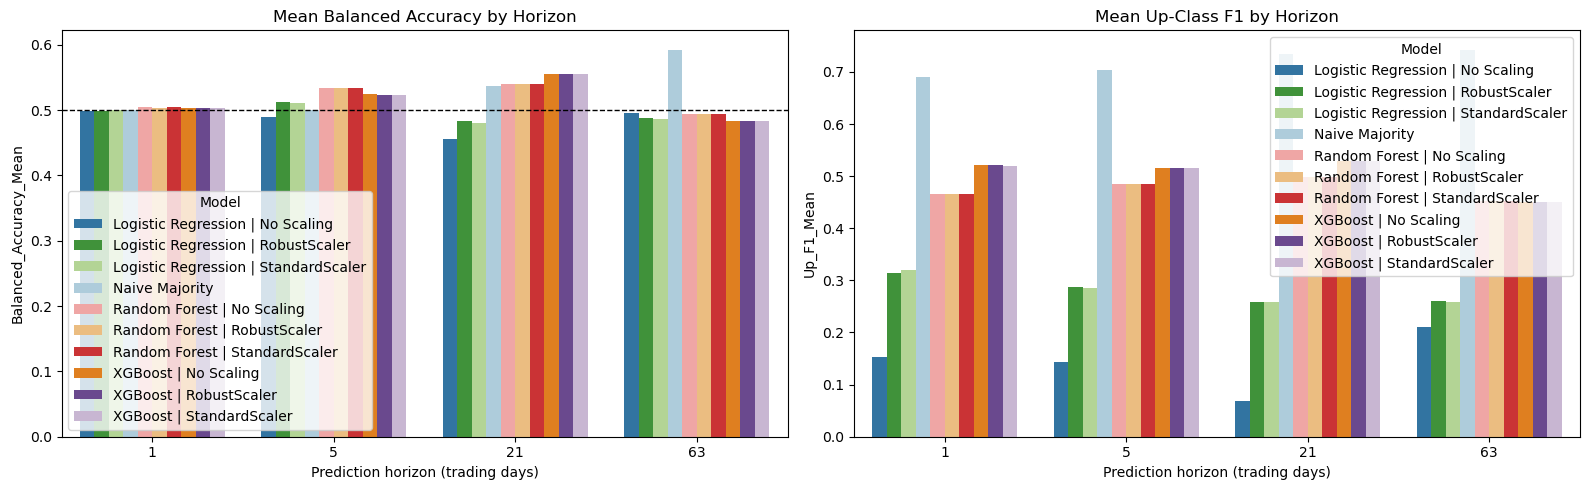

In [241]:
#Plot balanced accuracy and F1
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
#Balanced accuracy
sns.barplot(data=aggregate_metrics, x="Horizon", y="Balanced_Accuracy_Mean", hue="Model",
            palette=model_colors, ax=axes[0], errorbar=None)
axes[0].set_title("Mean Balanced Accuracy by Horizon")
axes[0].axhline(0.5, color="black", linestyle="--", linewidth=1)
#Up F1
sns.barplot(data=aggregate_metrics, x="Horizon", y="Up_F1_Mean", hue="Model",
            palette=model_colors, ax=axes[1], errorbar=None)
axes[1].set_title("Mean Up-Class F1 by Horizon")
for ax in axes:
    ax.set_xlabel("Prediction horizon (trading days)")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

In [169]:
#Pooled predictions across all train/valid folds for each layer/horizon/model
pooled_rows = []
for (layer_name, h, model_name), grp in predictions_df.groupby(["Layer", "Horizon", "Model"]):
    cm = confusion_matrix(grp["y_true"], grp["y_pred"], labels=[0, 1])
    pooled_rows.append({
        "Layer": layer_name, "Horizon": h, "Model": model_name,
        "TN": cm[0, 0], "FP": cm[0, 1], "FN": cm[1, 0], "TP": cm[1, 1],
        "Accuracy": accuracy_score(grp["y_true"], grp["y_pred"]),
        "Up_Precision": precision_score(grp["y_true"], 
                                        grp["y_pred"], pos_label=1, zero_division=0)})
pooled_summary = pd.DataFrame(pooled_rows)

In [59]:
# Get best model by mean fold accuracy per layer/horizon
best_by_combo = (aggregate_metrics.sort_values("Accuracy_Mean", ascending=False).groupby(
    ["Layer", "Horizon"], as_index=False).first()[["Layer", "Horizon", "Model"]])

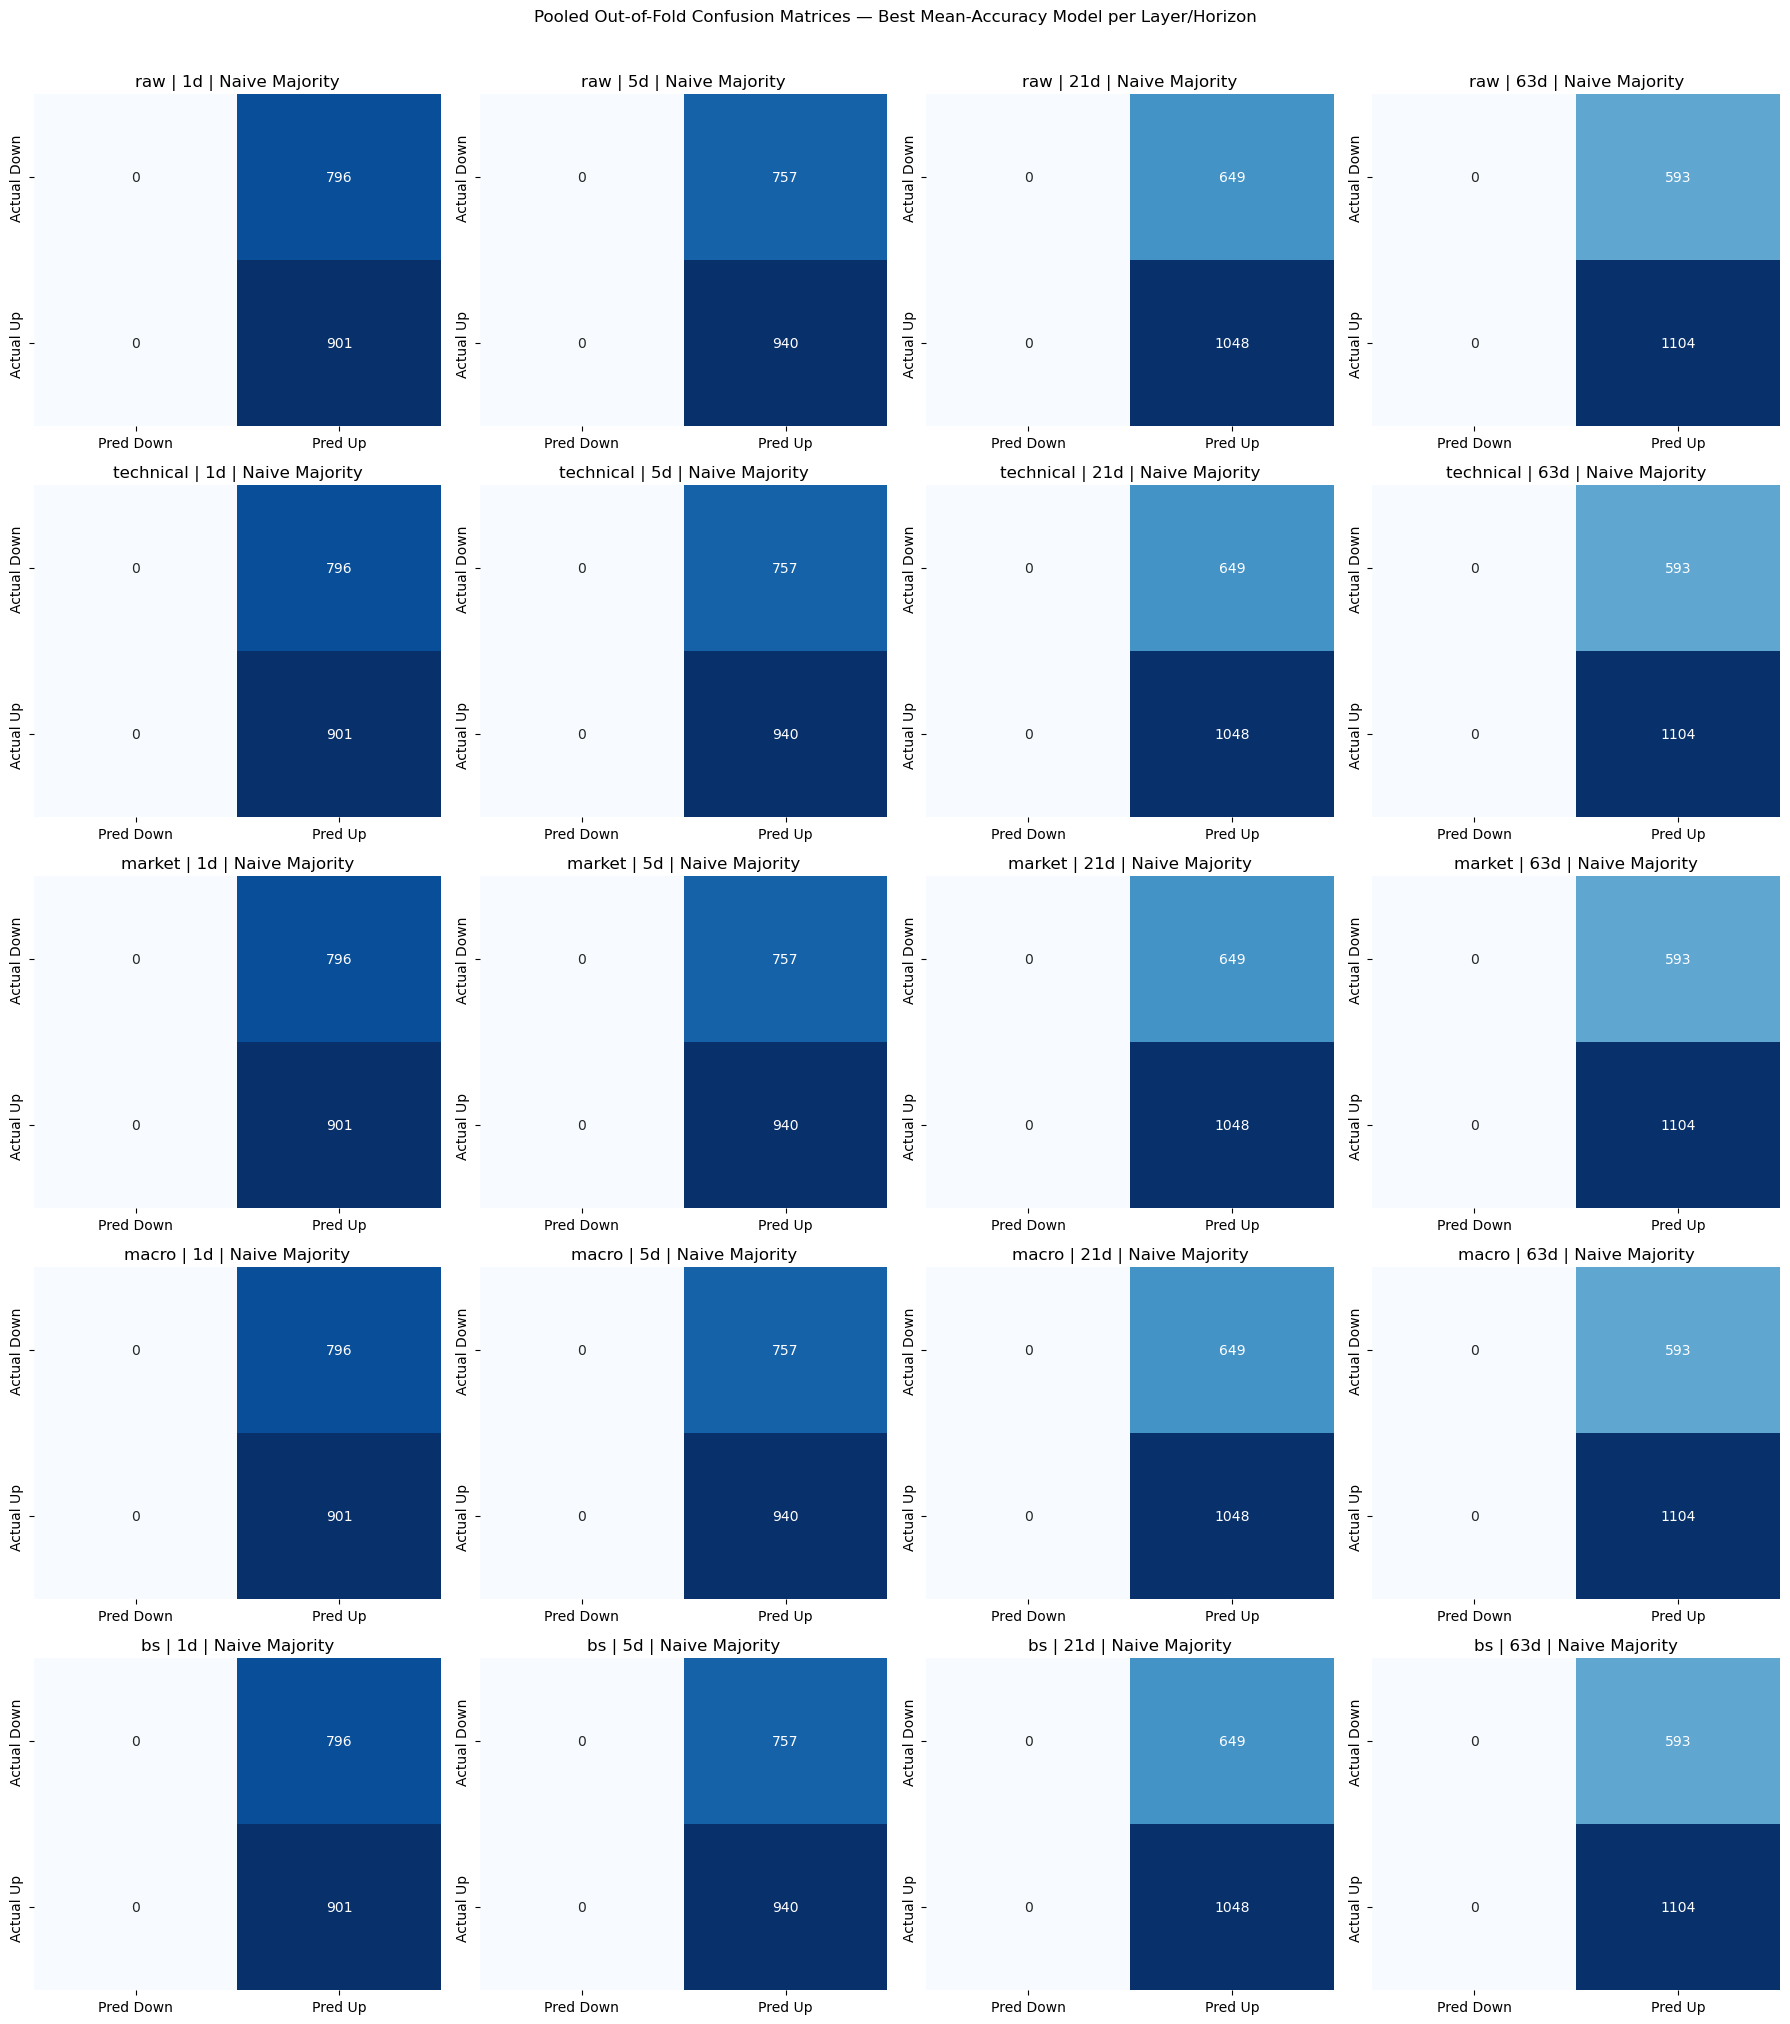

In [60]:
#Make pooled confusion matrix for best model
nrows = len(layer_feat)

fig, axes = plt.subplots(nrows, len(horizons), figsize=(18, 4 * nrows))

for i, layer_name in enumerate(layer_feat):
    for j, h in enumerate(horizons):
        ax = axes[i, j]
        
        chosen = best_by_combo[(best_by_combo["Layer"] == layer_name) 
        & (best_by_combo["Horizon"] == h)]
        if chosen.empty:
            ax.axis("off")
            continue
        model_name = chosen.iloc[0]["Model"]
        
        grp = predictions_df[(predictions_df["Layer"] == layer_name) &
        (predictions_df["Horizon"] == h) &
        (predictions_df["Model"] == model_name)]
        cm = confusion_matrix(grp["y_true"], grp["y_pred"], labels=[0, 1])
        
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                    xticklabels=["Pred Down", "Pred Up"], 
                    yticklabels=["Actual Down", "Actual Up"])
        ax.set_title(f"{layer_name} | {h}d | {model_name}")
        ax.set_xlabel("")
        ax.set_ylabel("")
fig.suptitle("Pooled Out-of-Fold Confusion Matrices — Best Mean-Accuracy Model per Layer/Horizon", y=1.01)
plt.tight_layout()
plt.show()

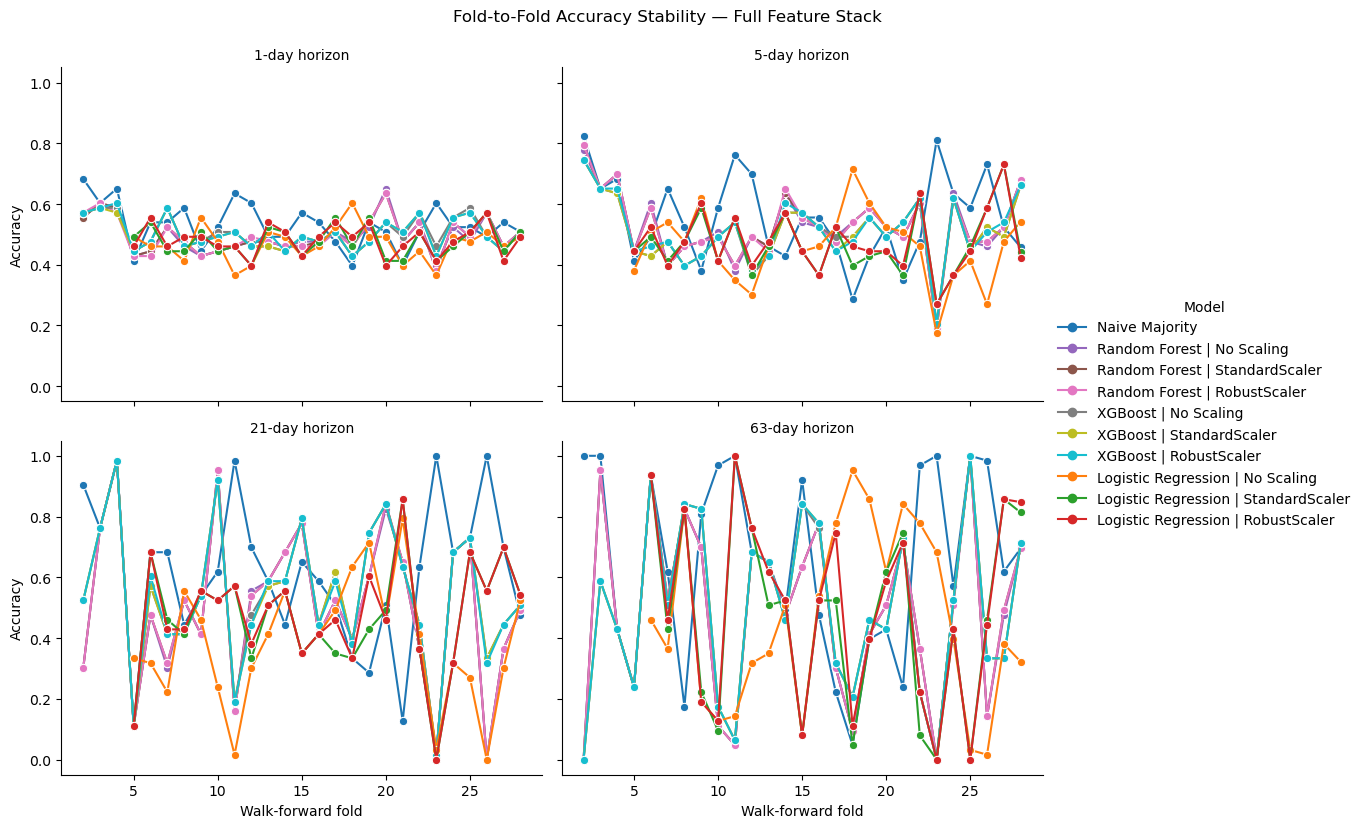

In [61]:
# Fold stability check - show each model's accuracy across folds for full feature 

full_layer = metrics_df[metrics_df["Layer"] == "bs"]
g = sns.relplot(data=full_layer, x="Fold", y="Accuracy", hue="Model", col="Horizon",
    kind="line", marker="o", col_wrap=2, palette=model_colors,
    facet_kws={"sharey": True}, height=4, aspect=1.35)
g.set_axis_labels("Walk-forward fold", "Accuracy")
g.set_titles("{col_name}-day horizon")
g.fig.suptitle("Fold-to-Fold Accuracy Stability — Full Feature Stack", y=1.03)
plt.show()

In [62]:
# Mean classification-report metrics by layer/horizon/model
report_summary = (reports_df.groupby(["Layer", "Horizon", "Model"], as_index=False)
                  .mean(numeric_only=True) )

display(report_summary.sort_values(["Horizon", "Layer", "Up_F1_Report"], 
                                   ascending=[True, True, False]).head(40))

,Layer,Horizon,Model,Fold,Down_Precision,Down_Recall,Down_F1,Up_Precision_Report,Up_Recall_Report,Up_F1_Report,Macro_F1,Weighted_F1
3,bs,1,Naive Majority,15.0,0.000000,0.000000,0.000000,0.530884,1.000000,0.690750,0.345375,0.371018
7,bs,1,XGBoost | No Scaling,15.0,0.482933,0.468427,0.437241,0.540306,0.542155,0.516600,0.476920,0.482241
8,bs,1,XGBoost | RobustScaler,15.0,0.483615,0.471387,0.438177,0.541111,0.539946,0.514736,0.476457,0.481827
9,bs,1,XGBoost | StandardScaler,15.0,0.480947,0.470636,0.436965,0.538350,0.535935,0.511658,0.474311,0.479439
5,bs,1,Random Forest | RobustScaler,15.0,0.459259,0.510031,0.438538,0.537973,0.496516,0.466456,0.452497,0.454591
4,bs,1,Random Forest | No Scaling,15.0,0.457603,0.514880,0.440299,0.543048,0.493353,0.465214,0.452756,0.454829
6,bs,1,Random Forest | StandardScaler,15.0,0.460386,0.513863,0.439972,0.539434,0.494494,0.464542,0.452257,0.454150
1,bs,1,Logistic Regression | RobustScaler,16.5,0.487628,0.689875,0.544121,0.476675,0.312106,0.327166,0.435643,0.428033
2,bs,1,Logistic Regression | StandardScaler,16.5,0.487872,0.685073,0.536433,0.468747,0.314419,0.322308,0.429370,0.420313
0,bs,1,Logistic Regression | No Scaling,16.5,0.452607,0.791477,0.536363,0.203509,0.202580,0.159013,0.347688,0.332974


# ML Investigation

In [171]:
#Check our train/test sizes 
sample_size_summary = (metrics_df.groupby(["Horizon", "Model"]).agg(
    Folds=("Fold", "nunique"),
    Mean_Train=("N_Train", "mean"),
    Min_Train=("N_Train", "min"),
    Mean_Test=("N_Test", "mean"),
    Min_Test=("N_Test", "min"),
    Max_Test=("N_Test", "max"),).round(1).reset_index())

display(sample_size_summary)

,Horizon,Model,Folds,Mean_Train,Min_Train,Mean_Test,Min_Test,Max_Test
0,1,Logistic Regression | No Scaling,27,1051.4,304,62.8,59,63
1,1,Logistic Regression | RobustScaler,27,1051.4,304,62.8,59,63
2,1,Logistic Regression | StandardScaler,27,1051.4,304,62.8,59,63
3,1,Naive Majority,27,1133.0,314,62.9,59,63
4,1,Random Forest | No Scaling,27,1133.0,314,62.9,59,63
5,1,Random Forest | RobustScaler,27,1133.0,314,62.9,59,63
6,1,Random Forest | StandardScaler,27,1133.0,314,62.9,59,63
7,1,XGBoost | No Scaling,27,1133.0,314,62.9,59,63
8,1,XGBoost | RobustScaler,27,1133.0,314,62.9,59,63
9,1,XGBoost | StandardScaler,27,1133.0,314,62.9,59,63


In [173]:
# A look at models' fold performance metrics

def calculate_fold_metrics(group):
    y_true = group["y_true"]
    y_pred = group["y_pred"]

    return pd.Series({
        "N_Test": len(group),
        "Actual_Up_Pct": y_true.mean() * 100,
        "Predicted_Up_Pct": y_pred.mean() * 100,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Up_Precision": precision_score(
            y_true, y_pred, pos_label=1, zero_division=0),
        "Up_Recall": recall_score(
            y_true, y_pred, pos_label=1, zero_division=0),
        "Up_F1": f1_score(
            y_true, y_pred, pos_label=1, zero_division=0) })

fold_performance = (predictions_df.groupby(["Layer", "Horizon", "Model", "Fold"])
                    .apply(calculate_fold_metrics).reset_index())

display(fold_performance.sort_values(["Horizon", "Layer", "Model", "Fold"]).round(3))

/var/folders/04/9rdrv6m92fn8yfkfl9p9xv180000gn/T/ipykernel_74020/830020664.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(calculate_fold_metrics).reset_index())


,Layer,Horizon,Model,Fold,N_Test,Actual_Up_Pct,Predicted_Up_Pct,Accuracy,Up_Precision,Up_Recall,Up_F1
0,bs,1,Logistic Regression | No Scaling,5,63.0,41.270,63.492,0.492,0.425,0.654,0.515
1,bs,1,Logistic Regression | No Scaling,6,63.0,53.968,41.270,0.460,0.500,0.382,0.433
2,bs,1,Logistic Regression | No Scaling,7,63.0,53.968,0.000,0.460,0.000,0.000,0.000
3,bs,1,Logistic Regression | No Scaling,8,63.0,58.730,0.000,0.413,0.000,0.000,0.000
4,bs,1,Logistic Regression | No Scaling,9,63.0,44.444,0.000,0.556,0.000,0.000,0.000
...,...,...,...,...,...,...,...,...,...,...,...
5239,technical,63,XGBoost | StandardScaler,24,63.0,57.143,61.905,0.317,0.410,0.444,0.427
5240,technical,63,XGBoost | StandardScaler,25,63.0,100.000,79.365,0.794,1.000,0.794,0.885
5241,technical,63,XGBoost | StandardScaler,26,63.0,98.413,4.762,0.063,1.000,0.048,0.092
5242,technical,63,XGBoost | StandardScaler,27,63.0,61.905,0.000,0.381,0.000,0.000,0.000


In [175]:
#Summarize performance stability

stability_summary = (fold_performance.groupby(["Layer", "Horizon", "Model"]).agg(
    Num_Folds=("Fold", "nunique"),
    Mean_Accuracy=("Accuracy", "mean"),
    Std_Accuracy=("Accuracy", "std"),
    Min_Accuracy=("Accuracy", "min"),
    Max_Accuracy=("Accuracy", "max"),
    Mean_Up_Precision=("Up_Precision", "mean"),
    Std_Up_Precision=("Up_Precision", "std"),
    Mean_Up_Recall=("Up_Recall", "mean"),
    Mean_Predicted_Up_Pct=("Predicted_Up_Pct", "mean")).reset_index())

display(stability_summary.sort_values(["Horizon", "Layer", "Model"]).round(3))

,Layer,Horizon,Model,Num_Folds,Mean_Accuracy,Std_Accuracy,Min_Accuracy,Max_Accuracy,Mean_Up_Precision,Std_Up_Precision,Mean_Up_Recall,Mean_Predicted_Up_Pct
0,bs,1,Logistic Regression | No Scaling,24,0.469,0.056,0.365,0.603,0.204,0.289,0.203,20.503
1,bs,1,Logistic Regression | RobustScaler,24,0.481,0.049,0.397,0.571,0.477,0.178,0.312,31.126
2,bs,1,Logistic Regression | StandardScaler,24,0.478,0.050,0.397,0.571,0.469,0.181,0.314,31.461
3,bs,1,Naive Majority,27,0.531,0.072,0.397,0.683,0.531,0.072,1.000,100.000
4,bs,1,Random Forest | No Scaling,27,0.497,0.059,0.397,0.651,0.543,0.102,0.493,48.945
...,...,...,...,...,...,...,...,...,...,...,...,...
195,technical,63,Random Forest | RobustScaler,27,0.451,0.273,0.000,1.000,0.621,0.393,0.540,52.585
196,technical,63,Random Forest | StandardScaler,27,0.451,0.273,0.000,1.000,0.621,0.393,0.540,52.585
197,technical,63,XGBoost | No Scaling,27,0.468,0.286,0.000,0.952,0.623,0.396,0.568,55.697
198,technical,63,XGBoost | RobustScaler,27,0.468,0.286,0.000,0.952,0.623,0.396,0.568,55.697


In [177]:
#Closer investigation for problematic horizon

def diagnose_fold(g): #gives metrics for particular horizon
    yt = g["y_true"]
    yp = g["y_pred"]

    return pd.Series({
        "N_Test": len(g),
        "Actual_Up_Pct": yt.mean() * 100,
        "Actual_Down_Pct": (1 - yt.mean()) * 100,
        "Predicted_Up_Pct": yp.mean() * 100,
        "Accuracy": accuracy_score(yt, yp),
        "Up_Precision": precision_score(
            yt, yp, pos_label=1, zero_division=0),
        "Up_Recall": recall_score(
            yt, yp, pos_label=1, zero_division=0)})

#Look at 63d horizon
diagnostic_63d = (predictions_df[predictions_df["Horizon"] == 63]
                  .groupby(["Layer", "Model", "Fold"]).apply(diagnose_fold).reset_index())
display(diagnostic_63d.sort_values(["Layer", "Model", "Fold"]).round(3))

/var/folders/04/9rdrv6m92fn8yfkfl9p9xv180000gn/T/ipykernel_74020/2768819477.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .groupby(["Layer", "Model", "Fold"]).apply(diagnose_fold).reset_index())


,Layer,Model,Fold,N_Test,Actual_Up_Pct,Actual_Down_Pct,Predicted_Up_Pct,Accuracy,Up_Precision,Up_Recall
0,bs,Logistic Regression | No Scaling,6,63.0,93.651,6.349,49.206,0.460,0.903,0.475
1,bs,Logistic Regression | No Scaling,7,63.0,61.905,38.095,1.587,0.365,0.000,0.000
2,bs,Logistic Regression | No Scaling,8,63.0,17.460,82.540,0.000,0.825,0.000,0.000
3,bs,Logistic Regression | No Scaling,9,63.0,80.952,19.048,0.000,0.190,0.000,0.000
4,bs,Logistic Regression | No Scaling,10,63.0,96.825,3.175,9.524,0.127,1.000,0.098
...,...,...,...,...,...,...,...,...,...,...
1297,technical,XGBoost | StandardScaler,24,63.0,57.143,42.857,61.905,0.317,0.410,0.444
1298,technical,XGBoost | StandardScaler,25,63.0,100.000,0.000,79.365,0.794,1.000,0.794
1299,technical,XGBoost | StandardScaler,26,63.0,98.413,1.587,4.762,0.063,1.000,0.048
1300,technical,XGBoost | StandardScaler,27,63.0,61.905,38.095,0.000,0.381,0.000,0.000


In [179]:
#A look at prediction probabilities for 63d horizon

p63 = predictions_df[predictions_df["Horizon"] == 63].copy()

display(p63.groupby(["Layer", "Model"])["y_prob_up"].agg(
    ["count", "mean", "std", "min", "median", "max"]).round(3))

count   mean    std    min  median    max
Layer     Model                                                                          
bs        Logistic Regression | No Scaling       1445  0.364  0.113  0.065   0.351  0.877
          Logistic Regression | RobustScaler     1445  0.384  0.394  0.000   0.217  1.000
          Logistic Regression | StandardScaler   1445  0.383  0.404  0.000   0.198  1.000
          Naive Majority                            0    NaN    NaN    NaN     NaN    NaN
          Random Forest | No Scaling             1697  0.556  0.253  0.016   0.578  0.999
          Random Forest | RobustScaler           1697  0.557  0.253  0.016   0.579  0.999
          Random Forest | StandardScaler         1697  0.556  0.253  0.016   0.578  0.999
          XGBoost | No Scaling                   1697  0.565  0.379  0.001   0.644  1.000
          XGBoost | RobustScaler                 1697  0.565  0.379  0.001   0.644  0.999
          XGBoost | StandardScaler               1697  0.565  0.379  0.001   0.644  1.000
macro     Logistic Regression | No Scaling       1445  0.390  0.161  0.065   0.355  1.000
          Logistic Regression | RobustScaler     1445  0.385  0.392  0.000   0.223  1.000
          Logistic Regression | StandardScaler   1445  0.387  0.400  0.000   0.229  1.000
          Naive Majority                            0    NaN    NaN    NaN     NaN    NaN
          Random Forest | No Scaling             1697  0.543  0.252  0.026   0.552  1.000
          Random Forest | RobustScaler           1697  0.543  0.252  0.026   0.554  1.000
          Random Forest | StandardScaler         1697  0.543  0.251  0.026   0.554  1.000
          XGBoost | No Scaling                   1697  0.553  0.382  0.001   0.588  0.999
          XGBoost | RobustScaler                 1697  0.553  0.382  0.001   0.587  0.999
          XGBoost | StandardScaler               1697  0.553  0.382  0.001   0.588  0.999
market    Logistic Regression | No Scaling       1445  0.363  0.109  0.073   0.352  0.877
          Logistic Regression | RobustScaler     1445  0.316  0.342  0.000   0.165  1.000
          Logistic Regression | StandardScaler   1445  0.310  0.344  0.000   0.159  1.000
          Naive Majority                            0    NaN    NaN    NaN     NaN    NaN
          Random Forest | No Scaling             1697  0.479  0.261  0.036   0.429  0.998
          Random Forest | RobustScaler           1697  0.479  0.261  0.036   0.429  0.998
          Random Forest | StandardScaler         1697  0.479  0.261  0.036   0.429  0.998
          XGBoost | No Scaling                   1697  0.417  0.375  0.002   0.279  1.000
          XGBoost | RobustScaler                 1697  0.417  0.375  0.002   0.282  1.000
          XGBoost | StandardScaler               1697  0.417  0.375  0.002   0.282  1.000
raw       Logistic Regression | No Scaling       1697  0.397  0.101  0.214   0.371  0.880
          Logistic Regression | RobustScaler     1697  0.371  0.196  0.011   0.331  0.988
          Logistic Regression | StandardScaler   1697  0.371  0.196  0.011   0.331  0.988
          Naive Majority                            0    NaN    NaN    NaN     NaN    NaN
          Random Forest | No Scaling             1697  0.491  0.419  0.000   0.426  1.000
          Random Forest | RobustScaler           1697  0.491  0.419  0.000   0.426  1.000
          Random Forest | StandardScaler         1697  0.491  0.419  0.000   0.426  1.000
          XGBoost | No Scaling                   1697  0.525  0.409  0.004   0.526  0.999
          XGBoost | RobustScaler                 1697  0.525  0.409  0.004   0.526  0.999
          XGBoost | StandardScaler               1697  0.525  0.409  0.004   0.526  0.999
technical Logistic Regression | No Scaling       1445  0.363  0.108  0.073   0.352  0.877
          Logistic Regression | RobustScaler     1445  0.305  0.249  0.000   0.260  0.999
          Logistic Regression | StandardScaler   1445  0.299  0.247  0.000   0.258  0.99

In [191]:
#Investigate if changing probability threshold can help improve performance

HORIZON = 63 #focus on problematic horizon

THRESHOLDS = np.round(np.arange(0.30, 0.701, 0.05), 2)

#Set time frame
dev = predictions_df[(predictions_df["Horizon"] == HORIZON)].copy()

dev["Fold"] = pd.to_numeric(dev["Fold"], errors="coerce")
dev["y_true"] = pd.to_numeric(dev["y_true"], errors="coerce")
dev["y_pred"] = pd.to_numeric(dev["y_pred"], errors="coerce")
dev["y_prob_up"] = pd.to_numeric(dev["y_prob_up"], errors="coerce")

# Models that produce probabilities
prob_models = dev[dev["y_prob_up"].notna() & dev["y_true"].notna()].copy()

# Keep the two tree models for the first experiment
prob_models = prob_models[
    prob_models["Model"].str.contains("Random Forest|XGBoost",case=False, na=False)]

# Naive majority baseline
naive = dev[dev["Model"].str.contains("Naive Majority",case=False, na=False)].copy()

# walk-forward threshold selection

fold_results = []

group_columns = ["Layer", "Model"]

for (layer, model), group in prob_models.groupby(group_columns):

    group = group.dropna(
        subset=["Fold", "y_true", "y_prob_up"]).copy()

    # Sort folds chronologically by their fold number
    folds = sorted(group["Fold"].unique())

    for i, current_fold in enumerate(folds):

        # Need at least two earlier folds - immediately preceding fold is excluded
        # a conservative embargo for 63-day labels.
        if i < 2:
            continue

        eligible_folds = folds[:i - 1]

        historical = group[group["Fold"].isin(eligible_folds)]

        current = group[group["Fold"] == current_fold].copy()

        if historical.empty or current.empty:
            continue

        y_hist = historical["y_true"].astype(int)
        p_hist = historical["y_prob_up"]

        # Choose threshold using historical predictions only.
        candidate_scores = []

        for threshold in THRESHOLDS:

            hist_pred = (p_hist >= threshold).astype(int)

            candidate_scores.append({
                "Threshold": threshold,
                "Historical_Accuracy": accuracy_score(y_hist, hist_pred)})

        scores = pd.DataFrame(candidate_scores)

        # If tied, prefer the threshold closest to 0.50.
        best_threshold = (scores.sort_values(["Historical_Accuracy"],ascending=False).assign(
            Distance=lambda x: (x["Threshold"] - 0.50).abs()).sort_values(
            ["Historical_Accuracy", "Distance"], ascending=[False, True]).iloc[0]["Threshold"])

        # Evaluate on the current fold - not used to choose the threshold.
        y_test = current["y_true"].astype(int)
        p_test = current["y_prob_up"]

        tuned_pred = (p_test >= best_threshold).astype(int)
        default_pred = (p_test >= 0.50).astype(int)

        # Match the naive baseline to this layer and fold.
        baseline_fold = naive[(naive["Layer"] == layer) & (naive["Fold"] == current_fold)]

        baseline_accuracy = np.nan

        if not baseline_fold.empty:
            baseline_accuracy = accuracy_score(
                baseline_fold["y_true"].astype(int),
                baseline_fold["y_pred"].astype(int))

        fold_results.append({
            "Layer": layer,
            "Model": model,
            "Fold": current_fold,
            "N": len(current),
            "Selected_Threshold": best_threshold,

            "Tuned_Accuracy": accuracy_score(y_test, tuned_pred),
            
            "Default_Accuracy": accuracy_score(y_test, default_pred),
            
            "Naive_Accuracy": baseline_accuracy,

            "Tuned_Up_Precision": precision_score(y_test, tuned_pred, zero_division=0),
            
            "Default_Up_Precision": precision_score(y_test, default_pred, zero_division=0),

            "Tuned_Up_Recall": recall_score(y_test, tuned_pred, zero_division=0 ),
            
            "Default_Up_Recall": recall_score(y_test, default_pred, zero_division=0),

            "Tuned_Up_F1": f1_score(y_test, tuned_pred, zero_division=0),
            
            "Default_Up_F1": f1_score(y_test, default_pred, zero_division=0),

            "Tuned_Predicted_Up_Pct": (tuned_pred.mean() * 100),
            
            "Default_Predicted_Up_Pct": (default_pred.mean() * 100)})

walkforward_threshold_df = pd.DataFrame(fold_results)

if walkforward_threshold_df.empty:
    print("No results produced.")
else:
    print("Fold-level results:")
    display(walkforward_threshold_df.sort_values(["Layer", "Model", "Fold"])
            .round(3).reset_index(drop=True))

Fold-level results:


,Layer,Model,Fold,N,Selected_Threshold,Tuned_Accuracy,Default_Accuracy,Naive_Accuracy,Tuned_Up_Precision,Default_Up_Precision,Tuned_Up_Recall,Default_Up_Recall,Tuned_Up_F1,Default_Up_F1,Tuned_Predicted_Up_Pct,Default_Predicted_Up_Pct
0,bs,Random Forest | No Scaling,4,63,0.30,0.429,0.429,0.429,0.429,0.429,1.000,1.000,0.600,0.600,100.000,100.000
1,bs,Random Forest | No Scaling,5,63,0.30,0.238,0.238,0.238,0.238,0.238,1.000,1.000,0.385,0.385,100.000,100.000
2,bs,Random Forest | No Scaling,6,63,0.30,0.937,0.937,0.937,0.937,0.937,1.000,1.000,0.967,0.967,100.000,100.000
3,bs,Random Forest | No Scaling,7,63,0.30,0.556,0.524,0.619,1.000,1.000,0.282,0.231,0.440,0.375,17.460,14.286
4,bs,Random Forest | No Scaling,8,63,0.30,0.841,0.825,0.175,1.000,0.000,0.091,0.000,0.167,0.000,1.587,0.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
745,technical,XGBoost | StandardScaler,24,63,0.65,0.270,0.317,0.571,0.344,0.410,0.306,0.444,0.324,0.427,50.794,61.905
746,technical,XGBoost | StandardScaler,25,63,0.65,0.365,0.794,1.000,1.000,1.000,0.365,0.794,0.535,0.885,36.508,79.365
747,technical,XGBoost | StandardScaler,26,63,0.30,0.413,0.063,0.984,1.000,1.000,0.403,0.048,0.575,0.092,39.683,4.762
748,technical,XGBoost | StandardScaler,27,63,0.30,0.381,0.381,0.619,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


In [193]:
#Make summary comparison of previous threshold tune test
summary_rows = []

for (layer, model), group in prob_models.groupby(["Layer", "Model"]):
    
    evaluated = walkforward_threshold_df[(walkforward_threshold_df["Layer"] == layer)
    & (walkforward_threshold_df["Model"] == model)]

    if evaluated.empty:
        continue

    # Recover the evaluated fold predictions so pooled metrics use individual observations
    evaluated_folds = evaluated["Fold"].unique()

    test_rows = group[group["Fold"].isin(evaluated_folds)].copy()

    y_true = test_rows["y_true"].astype(int)
    probs = test_rows["y_prob_up"]

    # Apply the selected threshold for each fold
    tuned_predictions = []

    for _, row in evaluated.iterrows():
        fold_rows = test_rows[
            test_rows["Fold"] == row["Fold"]]

        tuned_predictions.extend((fold_rows["y_prob_up"]>= row["Selected_Threshold"]).
                                 astype(int).tolist())

    tuned_predictions = np.asarray(tuned_predictions)

    default_predictions = (probs >= 0.50).astype(int)

    # Baseline predictions on matching folds
    baseline_rows = naive[(naive["Layer"] == layer)
    & (naive["Fold"].isin(evaluated_folds))]

    summary_rows.append({
        "Layer": layer,
        "Model": model,
        "Evaluated_Folds": len(evaluated_folds),
        "N": len(test_rows),

        "Tuned_Accuracy": accuracy_score(y_true, tuned_predictions),
        
        "Default_Accuracy": accuracy_score(y_true, default_predictions),

        "Tuned_Up_Precision": precision_score(y_true, tuned_predictions, zero_division=0),
        
        "Default_Up_Precision": precision_score(y_true, default_predictions, zero_division=0),

        "Tuned_Up_Recall": recall_score(y_true, tuned_predictions, zero_division=0),
        
        "Default_Up_Recall": recall_score(y_true, default_predictions, zero_division=0),

        "Tuned_Up_F1": f1_score(y_true, tuned_predictions, zero_division=0),
        
        "Default_Up_F1": f1_score(y_true, default_predictions, zero_division=0),

        "Tuned_Predicted_Up_Pct": (tuned_predictions.mean() * 100),
        
        "Default_Predicted_Up_Pct": (default_predictions.mean() * 100),

        "Naive_Accuracy": (accuracy_score(baseline_rows["y_true"].astype(int),
                                          baseline_rows["y_pred"].astype(int))
                           if not baseline_rows.empty
                           else np.nan) })

threshold_summary_df = pd.DataFrame(summary_rows)

display(threshold_summary_df.sort_values(["Layer", "Model"]).round(3).reset_index(drop=True))

,Layer,Model,Evaluated_Folds,N,Tuned_Accuracy,Default_Accuracy,Tuned_Up_Precision,Default_Up_Precision,Tuned_Up_Recall,Default_Up_Recall,Tuned_Up_F1,Default_Up_F1,Tuned_Predicted_Up_Pct,Default_Predicted_Up_Pct,Naive_Accuracy
0,bs,Random Forest | No Scaling,25,1571,0.541,0.490,0.602,0.590,0.777,0.591,0.678,0.591,80.395,62.317,0.623
1,bs,Random Forest | RobustScaler,25,1571,0.541,0.490,0.602,0.590,0.777,0.592,0.678,0.591,80.395,62.444,0.623
2,bs,Random Forest | StandardScaler,25,1571,0.541,0.491,0.602,0.591,0.777,0.593,0.678,0.592,80.395,62.508,0.623
3,bs,XGBoost | No Scaling,25,1571,0.505,0.507,0.601,0.611,0.611,0.573,0.606,0.591,63.335,58.370,0.623
4,bs,XGBoost | RobustScaler,25,1571,0.505,0.507,0.602,0.611,0.605,0.573,0.604,0.591,62.572,58.307,0.623
5,bs,XGBoost | StandardScaler,25,1571,0.505,0.507,0.602,0.611,0.604,0.573,0.603,0.591,62.508,58.307,0.623
6,macro,Random Forest | No Scaling,25,1571,0.538,0.499,0.600,0.603,0.775,0.572,0.676,0.587,80.458,59.007,0.623
7,macro,Random Forest | RobustScaler,25,1571,0.538,0.500,0.600,0.604,0.775,0.573,0.676,0.588,80.458,59.007,0.623
8,macro,Random Forest | StandardScaler,25,1571,0.539,0.500,0.600,0.604,0.776,0.572,0.677,0.587,80.522,58.943,0.623
9,macro,XGBoost | No Scaling,25,1571,0.521,0.485,0.608,0.597,0.648,0.534,0.627,0.563,66.391,55.697,0.623


In [195]:
#What if we change step size from 63 to 126
new_step_size = 126

In [205]:
new_folds = make_folds(work_dates, step_size=126)
new_fold_summary = pd.DataFrame(new_folds, columns=["Test_Start", "Test_End", "Fold"])
display(new_fold_summary)
print(f"Development dates: {len(work_dates):,}")
print(f"Walk-forward folds: {len(new_folds)}")
print("Final holdout begins:", train_end.date())

,Test_Start,Test_End,Fold
0,2017-09-01,2018-03-05,1
1,2018-03-06,2018-08-31,2
2,2018-09-04,2019-03-06,3
3,2019-03-07,2019-09-04,4
4,2019-09-05,2020-03-05,5
5,2020-03-06,2020-09-02,6
6,2020-09-03,2021-03-05,7
7,2021-03-08,2021-09-02,8
8,2021-09-03,2022-03-04,9
9,2022-03-07,2022-09-02,10


Development dates: 2,012
Walk-forward folds: 14
Final holdout begins: 2024-09-01


In [275]:
nmodels = build_models()
print("Models to evaluate:")
for name in nmodels:
    print("-", name)

Models to evaluate:
- Naive Majority
- Logistic Regression | No Scaling
- Logistic Regression | StandardScaler
- Logistic Regression | RobustScaler
- Random Forest | No Scaling
- Random Forest | StandardScaler
- Random Forest | RobustScaler
- XGBoost | No Scaling
- XGBoost | StandardScaler
- XGBoost | RobustScaler


In [317]:
nmodel_names = list(nmodels.keys())
npalette = sns.color_palette("cubehelix", n_colors=len(nmodel_names))
nmodel_colors = dict(zip(nmodel_names, npalette))

In [279]:
#Rerun the previous walk-forward setup

#Set up variables to store results
nall_metrics = []
nall_predictions = []
nall_reports = []
nall_confusions = []

#use the layered feature previously made
for layer_name, feature_cols in layer_feat.items():
    print(f"\nLayer: {layer_name} ({len(feature_cols)} numeric features)")
    
    for h in horizons:
        
        target_col = f"direction_{h}d"
        label_end_col = f"label_end_{h}d"
        nmodel_dict = build_models()

        for nfold_start, nfold_end, nfold_num in new_folds: #the walk-forward folds previosuly made
            ntest_mask = panel["Date"].between(nfold_start, nfold_end, inclusive="both")
            # Keep only rows whose target has matured.
            ntest_df = panel.loc[ntest_mask & panel[target_col].notna()].copy()
            if ntest_df.empty:
                continue

            # Purge: every training target must be fully known before test start.
            ntrain_mask = ((panel["Date"] < nfold_start) & panel[target_col].notna()
                          & panel[label_end_col].notna() & (panel[label_end_col] < nfold_start) )
            ntrain_df = panel.loc[ntrain_mask].copy()
            if len(ntrain_df) < 252: #252 = 1 year's worth of trading days
                continue

            #Set up train/test sets
            x_ntrain = ntrain_df[feature_cols]
            y_ntrain = ntrain_df[target_col].astype(int)
            x_ntest = ntest_df[feature_cols]
            y_ntest = ntest_df[target_col].astype(int)

            for model_name, estimator in nmodel_dict.items():

                #handling missing value without imputation

                #Logreg cannot fit or predict with NaNs
                need_complete_rows = (model_name.startswith("Logistic Regression"))
                #make new sets where we drop all rows with null
                if need_complete_rows:
                    ntrain_valid = x_ntrain.notna().all(axis=1)
                    ntest_valid = x_ntest.notna().all(axis=1)
                    nx_train_model = x_ntrain.loc[ntrain_valid]
                    ny_train_model = y_ntrain.loc[ntrain_valid]
                    nx_test_model = x_ntest.loc[ntest_valid]
                    ny_test_model = y_ntest.loc[ntest_valid]
                else: #use normal set with nulls for models capable of handling NaNs
                    nx_train_model = x_ntrain
                    ny_train_model = y_ntrain
                    nx_test_model = x_ntest
                    ny_test_model = y_ntest

                #safeguard
                if len(nx_train_model) < 252 or len(nx_test_model) == 0:
                    continue
                if ny_train_model.nunique() < 2:
                    continue

                #the actual fit and predict
                if model_name == "Naive Majority":
                    estimator.fit(np.zeros((len(ny_train_model), 1)), ny_train_model)
                    pred = estimator.predict(np.zeros((len(ny_test_model), 1))).astype(int)
                    prob = None
                else: 
                    
                    estimator.fit(nx_train_model, ny_train_model)
                    pred = estimator.predict(nx_test_model).astype(int)
                    prob = None
                    
                    if hasattr(estimator, "predict_proba"):
                        try:
                            prob = estimator.predict_proba(nx_test_model)[:, 1]
                        except (ValueError, IndexError):
                            prob = None

                #calculate metrics on the rows actually evaluated
                row = {
                    "Layer": layer_name, "Horizon": h, "Fold": fold_num,
                    "Test_Start": nfold_start, "Test_End": nfold_end,
                    "Model": model_name, "N_Train": len(ny_train_model), 
                    "N_Test": len(ny_test_model), 
                    "N_Train_Excluded_Missing": len(y_ntrain) - len(ny_train_model),
                    "N_Test_Excluded_Missing": len(y_ntest) - len(ny_test_model),
                    **metric_row(ny_test_model, pred, prob) }
                
                nall_metrics.append(row)
                #Store predictions only for observations actually evaluated
                npred_frame = ntest_df.loc[ny_test_model.index, ["Date"]].copy()
                
                npred_frame["Layer"] = layer_name
                npred_frame["Horizon"] = h
                npred_frame["Fold"] = nfold_num
                npred_frame["Model"] = model_name
                npred_frame["y_true"] = ny_test_model.to_numpy()
                npred_frame["y_pred"] = pred
                npred_frame["y_prob_up"] = prob if prob is not None else np.nan
                
                nall_predictions.append(npred_frame)
                #classification report
                nreport = classification_report(ny_test_model, pred, labels=[0, 1], 
                                               target_names=["Down", "Up"],
                                               output_dict=True, zero_division=0)
                
                #store results into one place
                nall_reports.append({
                    "Layer": layer_name, "Horizon": h, "Fold": nfold_num, "Model": model_name,
                    "Down_Precision": nreport["Down"]["precision"],
                    "Down_Recall": nreport["Down"]["recall"],
                    "Down_F1": nreport["Down"]["f1-score"],
                    "Up_Precision_Report": nreport["Up"]["precision"],
                    "Up_Recall_Report": nreport["Up"]["recall"],
                    "Up_F1_Report": nreport["Up"]["f1-score"],
                    "Macro_F1": nreport["macro avg"]["f1-score"],
                    "Weighted_F1": nreport["weighted avg"]["f1-score"],})
                #for confusion matrix
                ncm = confusion_matrix(ny_test_model, pred, labels=[0, 1])
                nall_confusions.append({
                    "Layer": layer_name, "Horizon": h, "Fold": nfold_num, "Model": model_name,
                    "TN": ncm[0, 0], "FP": ncm[0, 1], "FN": ncm[1, 0], "TP": ncm[1, 1]})

#Put results into dataframe format
nmetrics_df = pd.DataFrame(nall_metrics)
npredictions_df = pd.concat(nall_predictions, ignore_index=True) if nall_predictions else pd.DataFrame()
nreports_df = pd.DataFrame(nall_reports)
nconfusions_df = pd.DataFrame(nall_confusions)

if nmetrics_df.empty:
    raise RuntimeError("No metrics were generated")


Layer: raw (5 numeric features)

Layer: technical (20 numeric features)

Layer: market (32 numeric features)

Layer: macro (40 numeric features)

Layer: bs (44 numeric features)


In [281]:
#Table gives naive model performance and non-naive model that performed
#best in each layer per horizon

# Summarize metrics across walk-forward folds
nlayer_summary = (nmetrics_df.groupby(["Layer", "Horizon", "Model"], as_index=False)
    .agg(Accuracy_Mean=("Accuracy", "mean"), Up_Precision_Mean=("Up_Precision", "mean"),
        Accuracy_SD=("Accuracy", "std"), Folds=("Fold", "nunique")))

# Separate the naive baseline
nbaseline = nlayer_summary[nlayer_summary["Model"] == "Naive Majority"].copy()

# Find the best non-baseline configuration for each layer/horizon
ncandidates = nlayer_summary[nlayer_summary["Model"] != "Naive Majority"].copy()

nbest_models = (ncandidates.sort_values("Accuracy_Mean", ascending=False)
               .drop_duplicates(["Layer", "Horizon"]))

# Keep baseline and best model per layer/horizon
table2 = pd.concat([nbaseline, nbest_models], ignore_index=True)

# Convert metrics to percentages
for col in ["Accuracy_Mean", "Up_Precision_Mean", "Accuracy_SD"]:
    table2[col] = (table2[col] * 100).round(2)

table2 = table2.sort_values(["Horizon", "Layer", "Model"]).reset_index(drop=True)

display(table2)

,Layer,Horizon,Model,Accuracy_Mean,Up_Precision_Mean,Accuracy_SD,Folds
0,bs,1,Naive Majority,52.51,52.51,5.89,1
1,bs,1,XGBoost | RobustScaler,51.34,54.72,4.08,1
2,macro,1,Naive Majority,52.51,52.51,5.89,1
3,macro,1,Random Forest | StandardScaler,50.79,54.55,5.50,1
4,market,1,Naive Majority,52.51,52.51,5.89,1
5,market,1,XGBoost | No Scaling,50.30,53.33,4.16,1
6,raw,1,Naive Majority,52.51,52.51,5.89,1
7,raw,1,XGBoost | RobustScaler,52.09,54.87,3.86,1
8,technical,1,Naive Majority,52.51,52.51,5.89,1
9,technical,1,XGBoost | No Scaling,49.27,52.52,2.94,1


In [291]:
#combine model comparisons across folds
naggregate_metrics = (nmetrics_df.groupby(["Layer", "Horizon", "Model"], as_index=False).agg(
    nAccuracy_Mean=("Accuracy", "mean"),
    nAccuracy_SD=("Accuracy", "std"),
    nBalanced_Accuracy_Mean=("Balanced_Accuracy", "mean"),
    nUp_Precision_Mean=("Up_Precision", "mean"),
    nUp_Recall_Mean=("Up_Recall", "mean"),
    nUp_F1_Mean=("Up_F1", "mean"),
    nROC_AUC_Mean=("ROC_AUC", "mean"),
    nFolds=("Fold", "nunique") ))

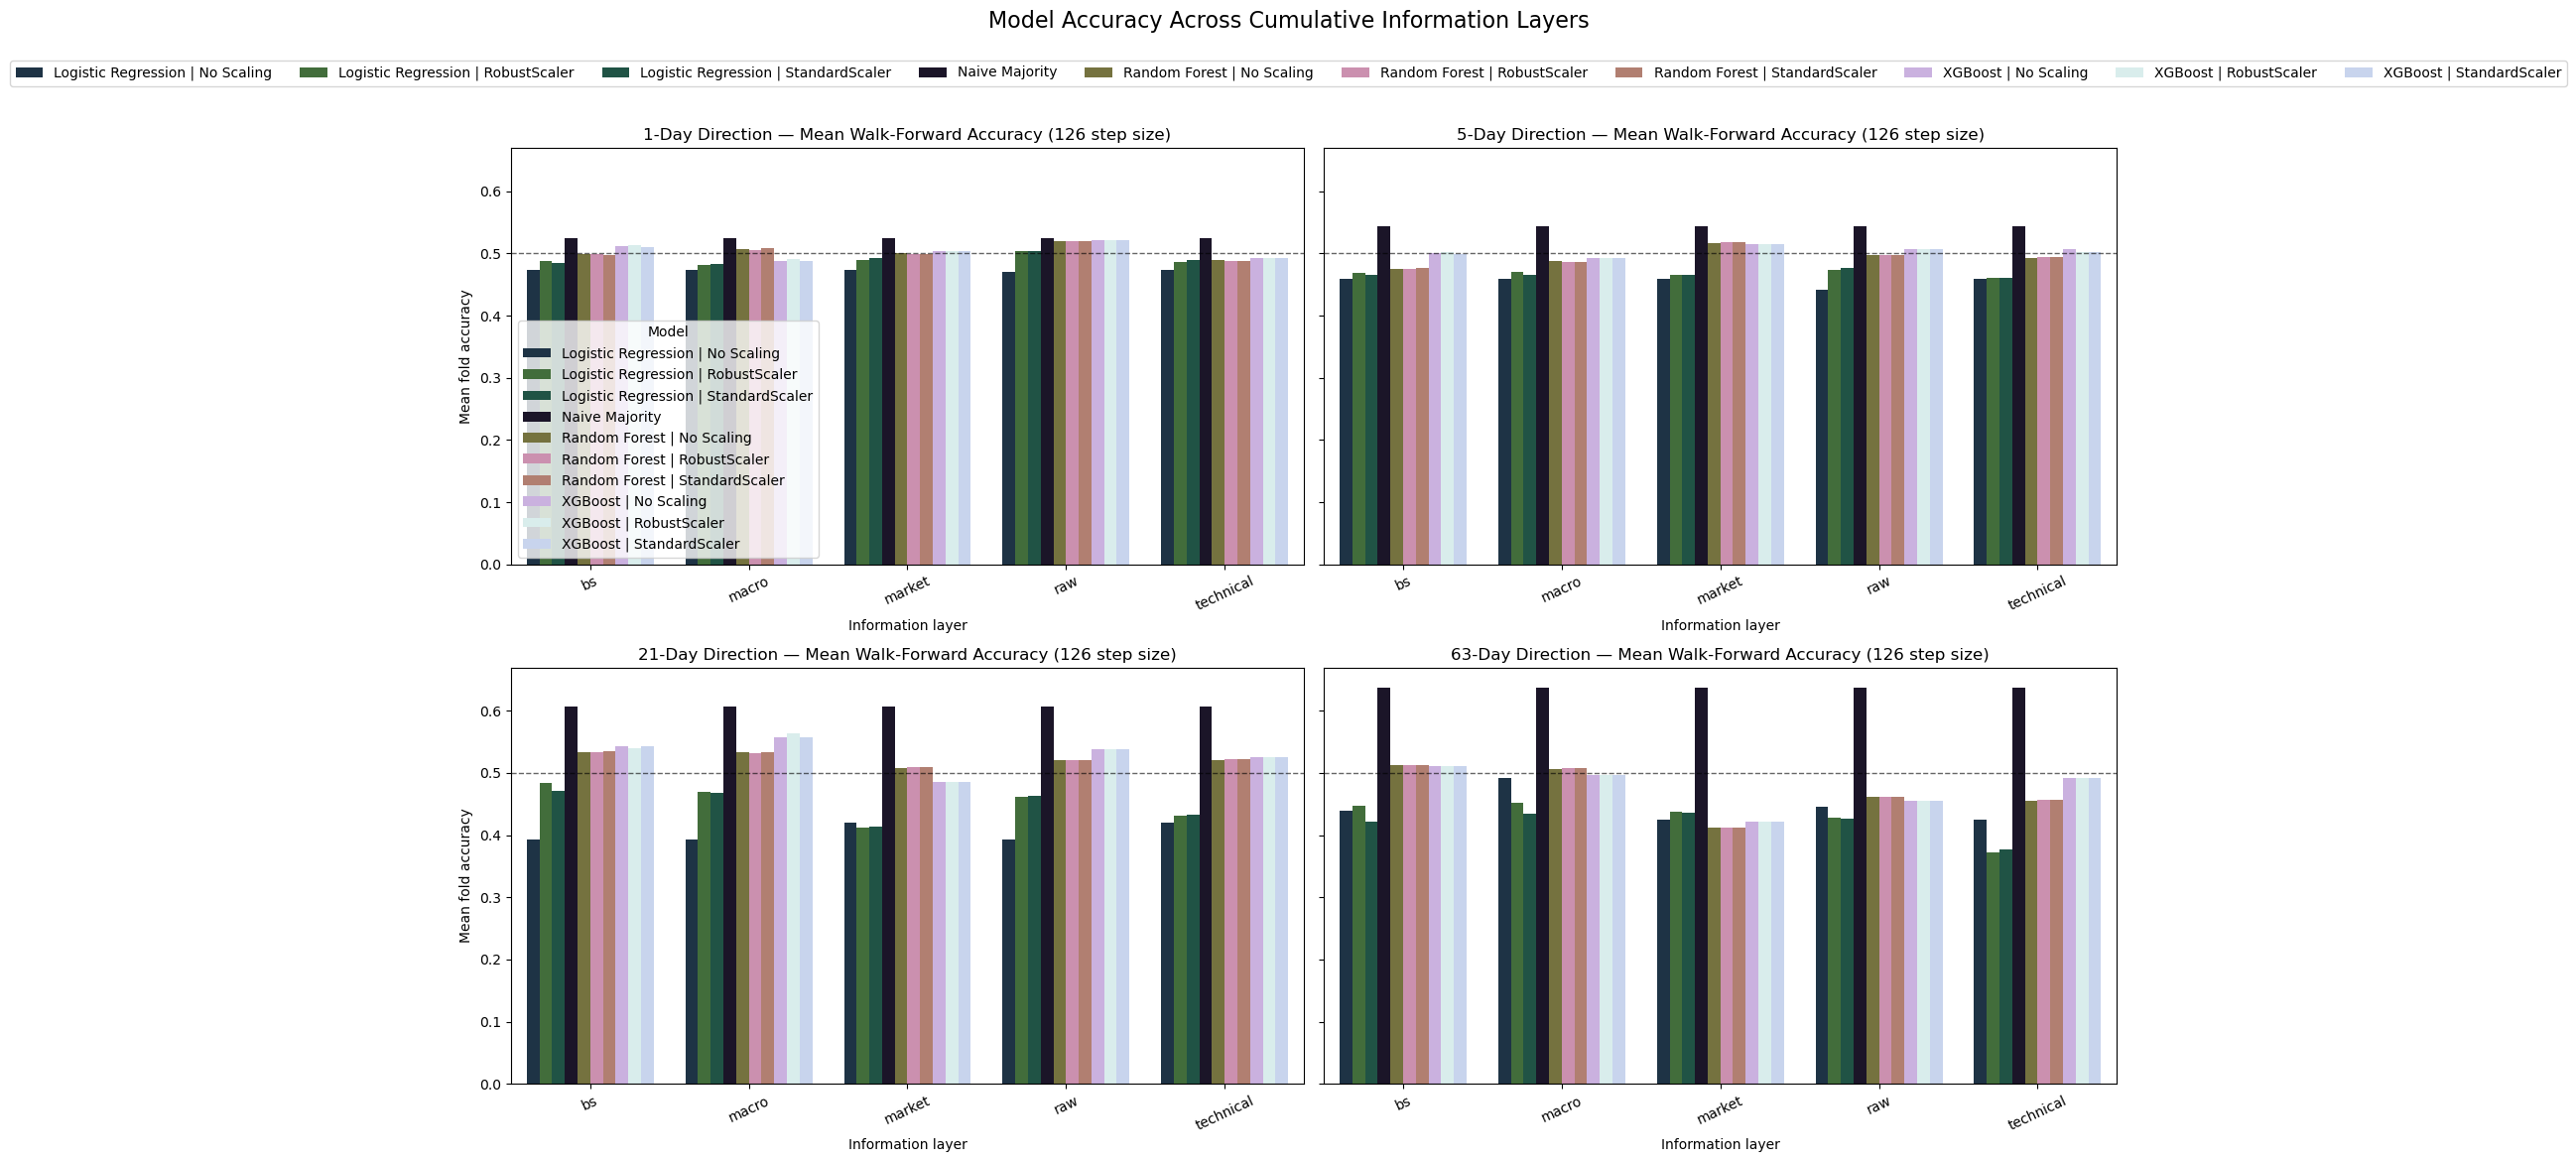

In [319]:
#Plot accuracy by layer and horizon, separate panel per horizon
fig, axes = plt.subplots(2, 2, figsize=(17, 11), sharey=True)
for ax, h in zip(axes.flat, horizons):
    nsub = naggregate_metrics[naggregate_metrics["Horizon"] == h]
    sns.barplot(nsub, x="Layer", y="nAccuracy_Mean", hue="Model",
    palette=nmodel_colors, ax=ax, errorbar=None)
    ax.set_title(f"{h}-Day Direction — Mean Walk-Forward Accuracy (126 step size)")
    ax.set_xlabel("Information layer")
    ax.set_ylabel("Mean fold accuracy")
    ax.tick_params(axis="x", rotation=25)
    ax.axhline(0.5, color="black", linestyle="--", linewidth=1, alpha=0.6)
    if ax.get_legend() and ax is not axes.flat[0]:
        ax.get_legend().remove()
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=len(labels), bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Model Accuracy Across Cumulative Information Layers", y=1.06, fontsize=16)
plt.tight_layout()
plt.show()

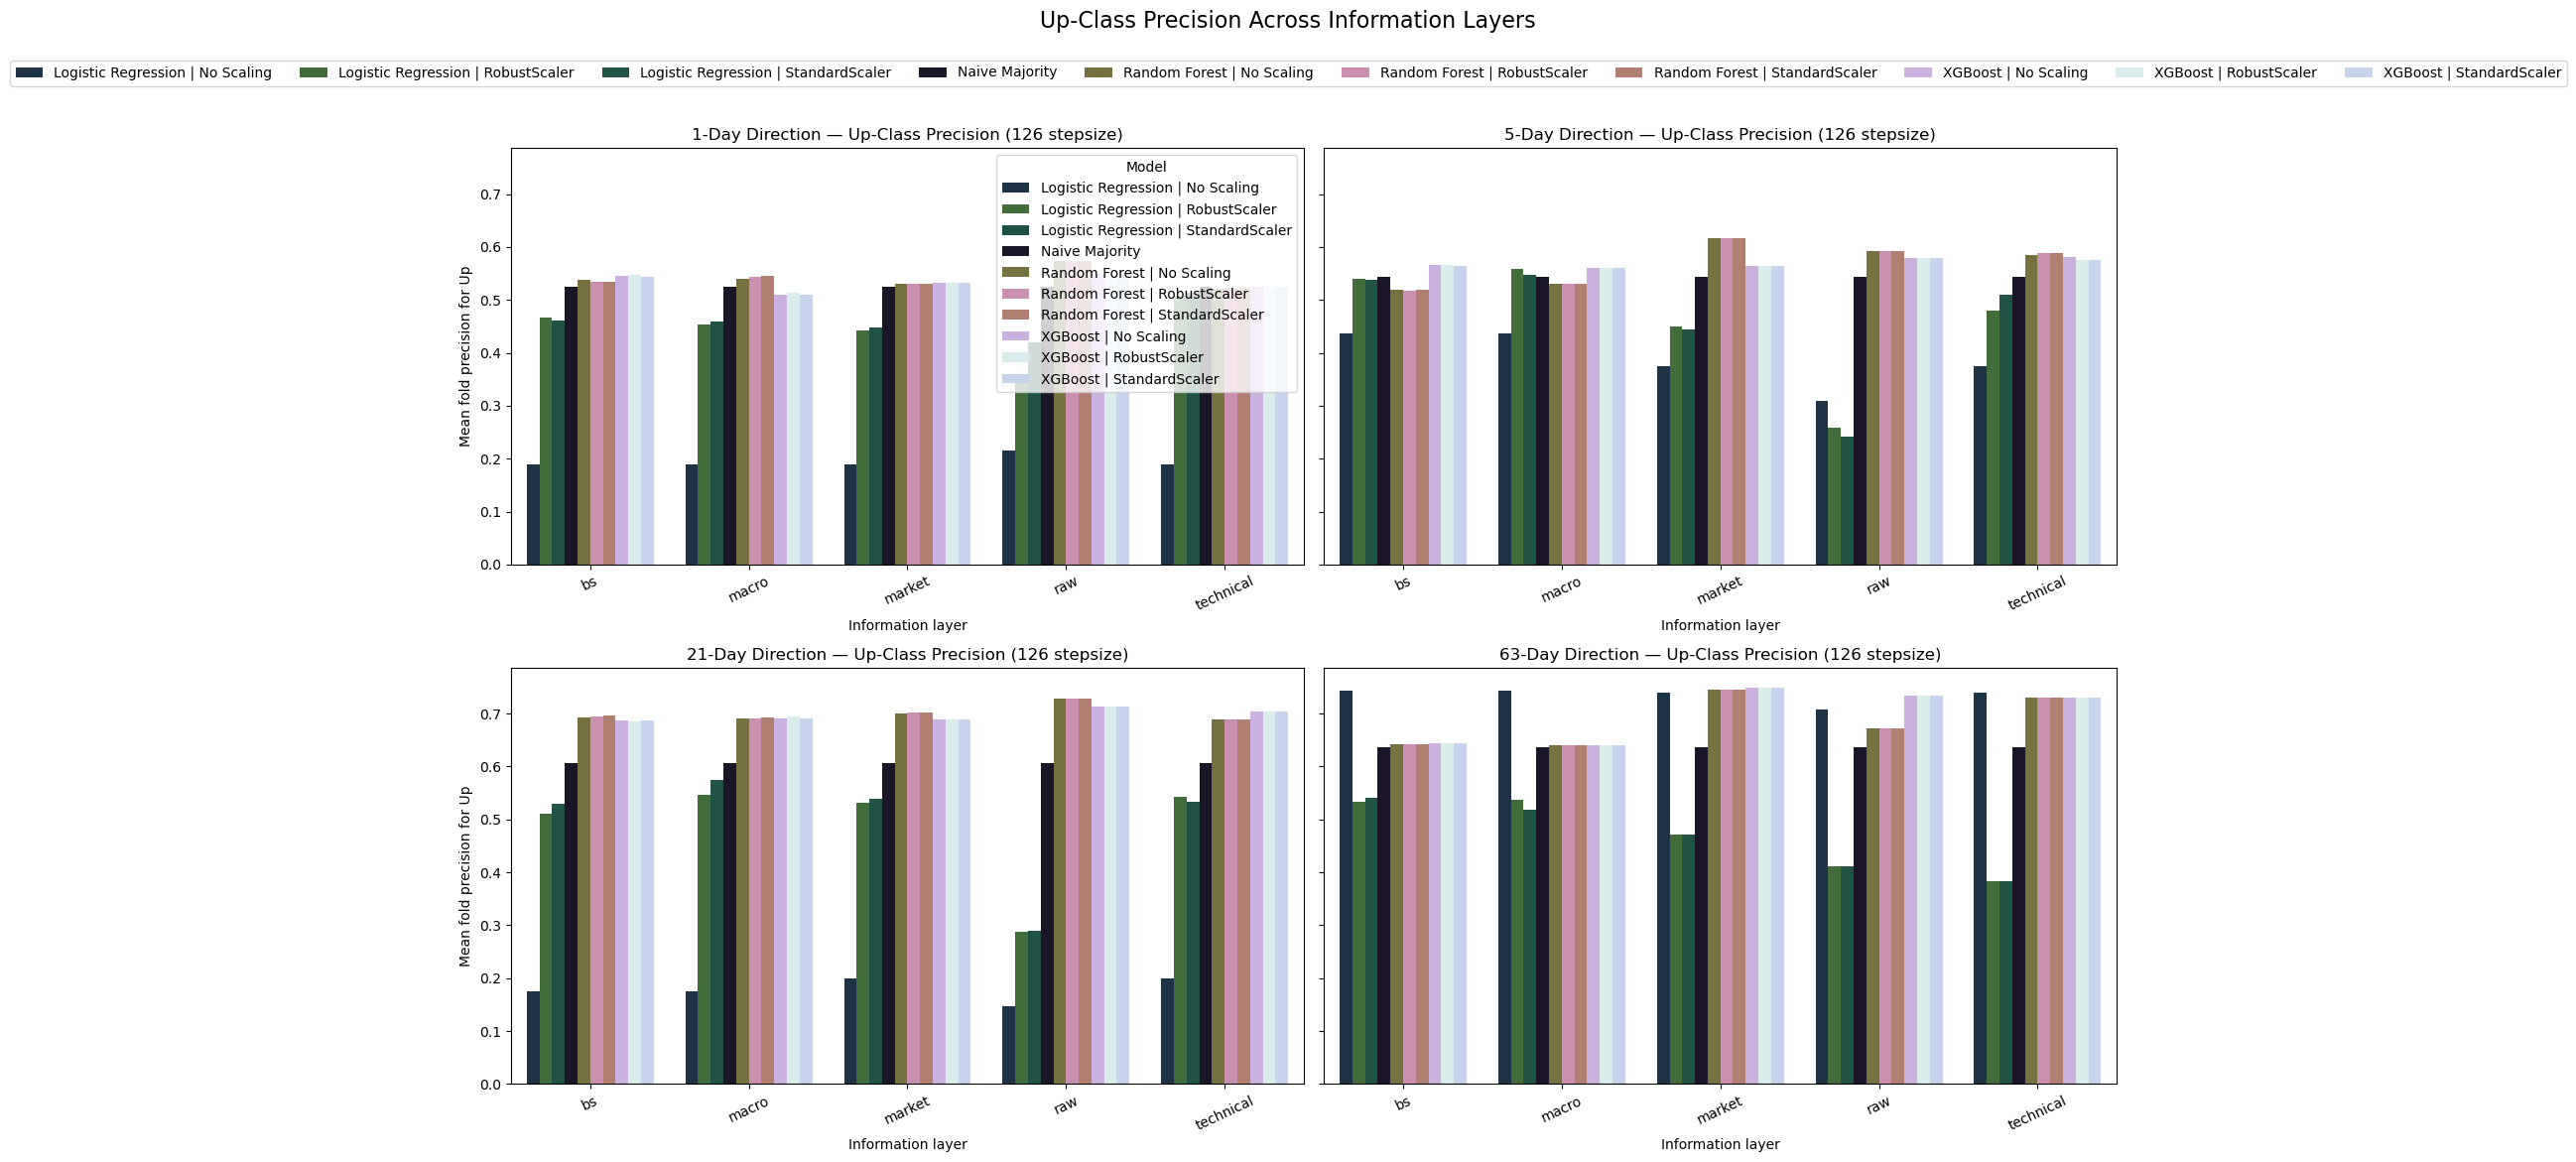

In [321]:
#Plot Up-class precision comparison
fig, axes = plt.subplots(2, 2, figsize=(17, 11), sharey=True)
for ax, h in zip(axes.flat, horizons):
    nsub = naggregate_metrics[naggregate_metrics["Horizon"] == h]
    sns.barplot(data=nsub, x="Layer", y="nUp_Precision_Mean", hue="Model",
        palette=nmodel_colors, ax=ax, errorbar=None)
    ax.set_title(f"{h}-Day Direction — Up-Class Precision (126 stepsize)")
    ax.set_xlabel("Information layer")
    ax.set_ylabel("Mean fold precision for Up")
    ax.tick_params(axis="x", rotation=25)
    if ax.get_legend() and ax is not axes.flat[0]:
        ax.get_legend().remove()
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=len(labels), bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Up-Class Precision Across Information Layers", y=1.06, fontsize=16)
plt.tight_layout()
plt.show()

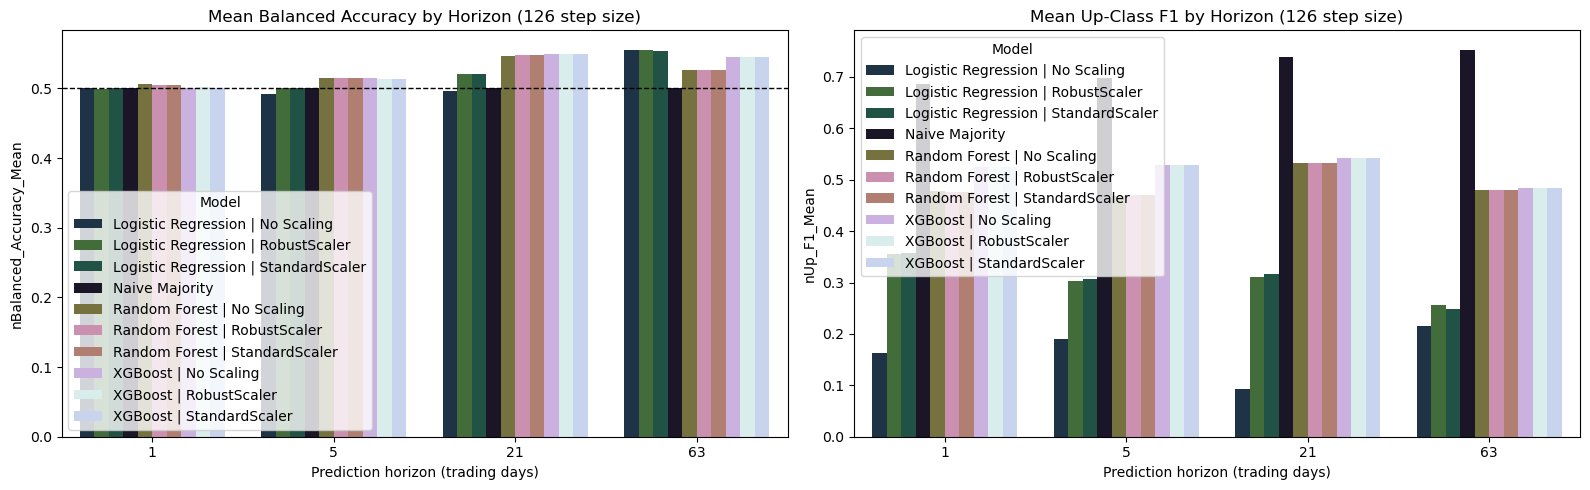

In [323]:
#Plot balanced accuracy and F1
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
#Balanced accuracy
sns.barplot(data=naggregate_metrics, x="Horizon", y="nBalanced_Accuracy_Mean", hue="Model",
            palette=nmodel_colors, ax=axes[0], errorbar=None)
axes[0].set_title("Mean Balanced Accuracy by Horizon (126 step size)")
axes[0].axhline(0.5, color="black", linestyle="--", linewidth=1)
#Up F1
sns.barplot(data=naggregate_metrics, x="Horizon", y="nUp_F1_Mean", hue="Model",
            palette=nmodel_colors, ax=axes[1], errorbar=None)
axes[1].set_title("Mean Up-Class F1 by Horizon (126 step size)")
for ax in axes:
    ax.set_xlabel("Prediction horizon (trading days)")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()